<style>
.jp-RenderedHTMLCommon h1,.jp-RenderedHTMLCommon h2,.text_cell_render h1,.text_cell_render h2 {
font-family: "Times New Roman", "Liberation Serif", "Nimbus Roman", Georgia, serif;
font-weight: bold; color: black; padding-bottom: .24em; border-bottom: 0;
}
.jp-RenderedHTMLCommon hr,.text_cell_render hr {border: 0; border-top: 1px solid black;}
.jp-RenderedHTMLCommon,.text_cell_render {color: black;}
.jp-RenderedHTMLCommon nav,.text_cell_render nav {margin: 1em 0;}
.jp-RenderedHTMLCommon a,.text_cell_render a {color: inherit; text-decoration: underline;}
</style>

<a id="carnet"></a>

# Parallel edit distance from a single pair to genome collections

<hr>

La distance de Levenshtein compte le nombre minimal d’insertions, de suppressions et de substitutions entre deux chaînes. NvPD calcule les scores d’une ligne en parallèle en s’appuyant sur les dernières occurrences des lettres. Le carnet examine le coût de cette récurrence sur processeur, accélérateur et nœuds distribués, puis suit la distance jusqu’à la construction d’arbres entre génomes.

Les mesures synthétiques couvrent quatre longueurs de 5 000 à un million de bases et trois taux d’erreur. Les fenêtres humaines et la collection de phages apportent deux comparaisons sur séquences publiques. Les mesures de passage à l’échelle proviennent de ROMEO. La reconstruction par Hirschberg et la comparaison des méthodes sensibles à la distance utilisent un Apple M1 Pro. Les variantes d’un essai A/B partagent la même entrée et le même matériel.

<nav aria-label="Sommaire"><strong>Sommaire</strong><p>Calcul sur CPU. <a href="#distance-globale">Coût du calcul de la distance globale</a>, <a href="#echelle-openmp">Passage à l’échelle sur un processeur</a>, <a href="#openmp-long">Anti-diagonales et lignes de grande largeur</a>, <a href="#vectorisation">Vectorisation de la récurrence de dernière occurrence</a>, <a href="#hierarchie-memoire">Occupation mémoire et défauts du cache de données</a>, <a href="#trace-lineaire">Reconstruction de l’alignement en espace linéaire</a>, <a href="#instructions">Instructions et prédictions de branchement</a>.</p><p>Calcul sur GPU. <a href="#tuiles-cuda">Regroupement des lignes en tuiles CUDA</a>, <a href="#trace-cuda">Chronologie des appels hôte et des noyaux CUDA</a>, <a href="#localite-gpu">Localité des lectures en mémoire globale</a>, <a href="#front-gpu">Calcul par fronts de coût sur accélérateur</a>, <a href="#allocations-cuda">Réutilisation des tampons entre alignements</a>.</p><p>Portage et distribution. <a href="#kokkos">Portabilité de la récurrence avec Kokkos</a>, <a href="#mpi-fort">Passage à l’échelle fort entre nœuds</a>, <a href="#mpi-faible">Passage à l’échelle faible entre nœuds</a>.</p><p>Génomes et choix de la méthode. <a href="#chromosome">Distances entre assemblages d’un chromosome humain</a>, <a href="#assemblages-entiers">Comparaison de chromosomes humains entiers</a>, <a href="#methodes-distance">Méthodes exactes sensibles à la distance</a>, <a href="#phylogenie">Structure des distances entre génomes de phages</a>, <a href="#groupes-surveillance">Concordance avec les groupes de surveillance</a>, <a href="#synthese">Synthèse des critères de choix</a>.</p></nav>

L’exécution lit les CSV du dépôt et exporte les PNG dans [figures/](../figures/). Avec l’environnement décrit dans [notebooks/requirements.txt](requirements.txt), la commande est `python -m jupyter nbconvert --to notebook --execute --inplace CHEMIN/notebooks/profil_nvpd.ipynb`. CHEMIN désigne la racine du dépôt.

In [1]:
from pathlib import Path
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# nbconvert positionne le noyau dans le dossier du carnet, même si son appel vient d'ailleurs.
# Les interfaces qui exécutent le noyau hors du dépôt peuvent fournir CHPS_PROJECT_ROOT.
nv_anchor_paths = [Path.cwd()]
for nv_path_hint in [os.environ.get("CHPS_PROJECT_ROOT"), os.environ.get("JPY_SESSION_NAME"),
                     globals().get("__vsc_ipynb_file__")]:
    if nv_path_hint:
        nv_anchor_paths.append(Path(nv_path_hint).expanduser().resolve())
nv_roots = (candidate for start in nv_anchor_paths for candidate in (start, *start.parents))
ROOT = next((candidate for candidate in nv_roots
             if (candidate / "python/ct_plot.py").is_file() and (candidate / "CMakeLists.txt").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Indiquer la racine du projet dans CHPS_PROJECT_ROOT.")
sys.path.insert(0, str(ROOT / "python"))
import ct_plot
from ct_plot import COLORS, INK, PAPER, GUIDE, column_titles, label_panels, legend_above

ct_plot.use_style()
RES = ROOT / "results"
PROF = RES / "profile"
FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)
pd.options.display.float_format = "{:.3g}".format

def nv_save(figure, name):
    with ct_plot.atomic_png(FIG / (name + ".png")) as stream:
        figure.savefig(stream, format="png")
    plt.show()

def nv_csv(path):
    return pd.read_csv(path, keep_default_na=False)

def nv_band(axis, series, color, label, marker="o"):
    # Une abscisse regroupe les mesures indépendantes de la configuration.
    stats = series.groupby(level=0).agg(["median", "min", "max"])
    spread = [stats["median"]-stats["min"], stats["max"]-stats["median"]]
    axis.errorbar(stats.index, stats["median"], yerr=spread, marker=marker, color=color,
                  capsize=2, label=label, markeredgecolor=INK)

<a id="distance-globale"></a>

## Coût du calcul de la distance globale

<hr>

La figure 1 compare les durées des alignements sur les mêmes paires, d’abord selon leur longueur puis selon le taux d’erreur.

Pour une paire de longueurs $m,n$, le débit dense vaut $mn/(10^9 T)$ en GCUPS. Ce calcul suppose que la méthode visite toutes les cases. Edlib traite plusieurs positions par mot machine et WFA2-lib explore les fronts de coût.

L’alignement est global. Une insertion, une suppression ou une substitution coûte une unité. Deux symboles IUPAC doivent être identiques pour donner une correspondance. Sur CPU, edlib calcule la distance avec des opérations bit-parallèles. WFA2-lib utilise les fronts d’onde en mode distance d’édition exacte, sans heuristique. Dans cette première comparaison, la série GPU exécute NvPD. L’implémentation eWFA-GPU de l’article fourni fait l’objet de l’expérience sur les fronts de coût. [NvPD, Sadiq et coll.](https://doi.org/10.1007/s10586-019-02962-w) · [edlib, Šošić et Šikić](https://doi.org/10.1093/bioinformatics/btw753) · [WFA, Marco-Sola et coll.](https://doi.org/10.1093/bioinformatics/btaa777) · [eWFA-GPU, Aguado-Puig et coll.](https://doi.org/10.1109/ACCESS.2022.3182714)

La première campagne a produit 60 paires synthétiques avec une graine maîtresse de 2026. À un million de bases, la programmation dynamique dense sur CPU traite une paire par taux. Les deux bibliothèques et le GPU en traitent cinq. Le temps par paire commence après la lecture FASTA et couvre l’allocation ainsi que le retour du coût. Pour CUDA, le premier appel inclut l’initialisation du contexte.

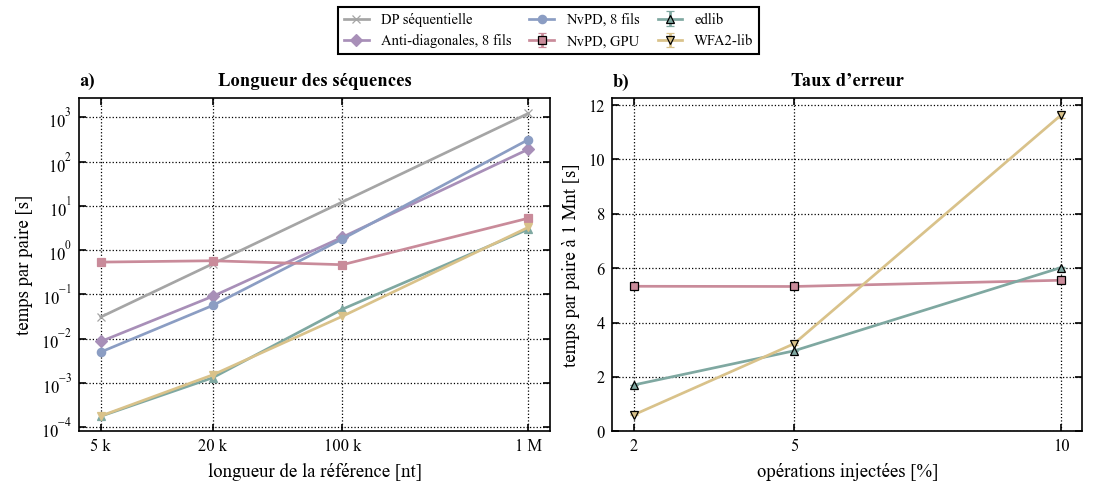

In [2]:
# Durée selon la longueur et le taux d'erreur (results/romeo/{cpu,gpu}-*.csv).
nv_runs = pd.concat([nv_csv(path) for path in sorted((RES / "romeo").glob("*-*.csv"))],
                    ignore_index=True)
assert nv_runs.status.eq("ok").all() and (nv_runs.seconds > 0).all()
assert nv_runs.groupby("input_sha256").distance.nunique().eq(1).all()
nv_methods = {
    "seq": ("DP séquentielle", COLORS[4], "x"), "diagonal": ("Anti-diagonales, 8 fils", COLORS[5], "D"),
    "nvpd-omp": ("NvPD, 8 fils", COLORS[0], "o"), "nvpd-cuda": ("NvPD, GPU", COLORS[1], "s"),
    "edlib": ("edlib", COLORS[2], "^"), "wfa2": ("WFA2-lib", COLORS[3], "v"),
}
nv_selected = nv_runs[nv_runs.threads.eq(8) | ~nv_runs.algorithm.isin(["diagonal", "nvpd-omp"])]
# Une seule valeur par paire et méthode, même quand une campagne répète sa mesure.
nv_pair = (nv_selected.groupby(["length", "rate", "rep", "algorithm", "input_sha256"], as_index=False)
           .agg(seconds=("seconds", "median"), distance=("distance", "first")))
nv_fig, nv_ax = plt.subplots(1, 2, figsize=(7.2, 3.2))
for nv_alg, (nv_name, nv_color, nv_marker) in nv_methods.items():
    nv_sub = nv_pair[nv_pair.algorithm.eq(nv_alg)]
    nv_len = nv_sub[nv_sub.rate.eq(.05) & nv_sub.rep.eq(1)].sort_values("length")
    assert nv_len.length.tolist() == [5000, 20000, 100000, 1000000]
    nv_ax[0].plot(nv_len.length, nv_len.seconds, marker=nv_marker, color=nv_color, label=nv_name)
    if nv_alg in ("nvpd-cuda", "edlib", "wfa2"):
        nv_err = nv_sub[nv_sub.length.eq(1000000)].set_index("rate")
        assert nv_err.groupby(level=0).size().eq(5).all()
        nv_err.index = nv_err.index * 100
        nv_band(nv_ax[1], nv_err.seconds, nv_color, nv_name, nv_marker)
nv_ax[0].set(xscale="log", yscale="log", xlabel="longueur de la référence [nt]", ylabel="temps par paire [s]")
nv_ax[0].set_xticks([5000, 20000, 100000, 1000000], ["5 k", "20 k", "100 k", "1 M"])
nv_ax[1].set(xlabel="opérations injectées [%]", ylabel="temps par paire à 1 Mnt [s]", ylim=(0, None))
nv_ax[1].set_xticks([2, 5, 10])
label_panels(nv_ax)
column_titles(nv_ax, ('Longueur des séquences', 'Taux d’erreur'))
legend_above(nv_fig, nv_ax, ncol=3)
nv_save(nv_fig, "01_temps_distance")

*Figure 1.* Le panneau a) suit la première paire de chaque longueur à 5 % d’erreur. Le panneau b) donne la médiane et les extrêmes sur cinq paires par taux à un million de bases.

<sub>Code : [scripts/synthetic.py](../scripts/synthetic.py), [src/baselines.cpp](../src/baselines.cpp), [bench/run.py](../bench/run.py), [results/romeo](../results/romeo/).</sub>

À un million de bases, WFA2-lib passe de 0,61 s à 11,64 s entre 2 et 10 % d’opérations injectées. Sur les mêmes groupes, edlib passe de 1,71 à 6,03 s, NvPD sur GPU de 5,34 à 5,56 s. NvPD parcourt toute la matrice. Les fronts de WFA grandissent avec la distance optimale. Le taux décrit les opérations tirées par le générateur, dont le nombre peut dépasser la distance minimale.

Le coût des méthodes denses conduit à examiner la répartition des colonnes entre les cœurs.

<p><strong><u>Synthèse.</u></strong> À un million de bases, l’algorithme le plus rapide varie avec le taux d’erreur.<br>La médiane la plus basse revient à WFA2-lib à 2 %, à edlib à 5 % et à NvPD CUDA à 10 % sur les cinq paires par taux.</p>

<a id="echelle-openmp"></a>

## Passage à l’échelle sur un processeur

<hr>

La figure 2 suit l’évolution du temps lorsque les fils OpenMP se partagent les colonnes d’une matrice.

Soit $T_p(m,n)$ le temps médian de trois essais de NvPD sur $p$ cœurs. À taille fixe, l’accélération vaut $S_p=T_1(m,n)/T_p(m,n)$, l’efficacité $S_p/p$. À travail fixe par cœur, le calcul garde 4 096 lignes et multiplie le nombre de colonnes par $p$. L’efficacité faible vaut alors $T_1(4096,4096)/T_p(4096,4096p)$. Les deux expériences gardent le même nombre de barrières de lignes lorsque $p$ varie, mais seule la seconde conserve le nombre de cases à traiter par cœur. [Cornell, mesures de passage à l’échelle](https://cvw.cac.cornell.edu/parallel/efficiency/scaling) · [Amdahl, 1967](https://doi.org/10.1145/1465482.1465560)

Les essais emploient la même variante à l’intérieur de chaque courbe, des fils attachés aux cœurs avec OpenMP et une phase de chauffe. Chaque processus vérifie sa distance et l’empreinte de ses entrées contre la référence avant la mise en commun des résultats. V1 utilise un index d’entiers sur quatre octets et une boucle vectorisable. V2 essaie de représenter les écarts de l’index sur un octet.

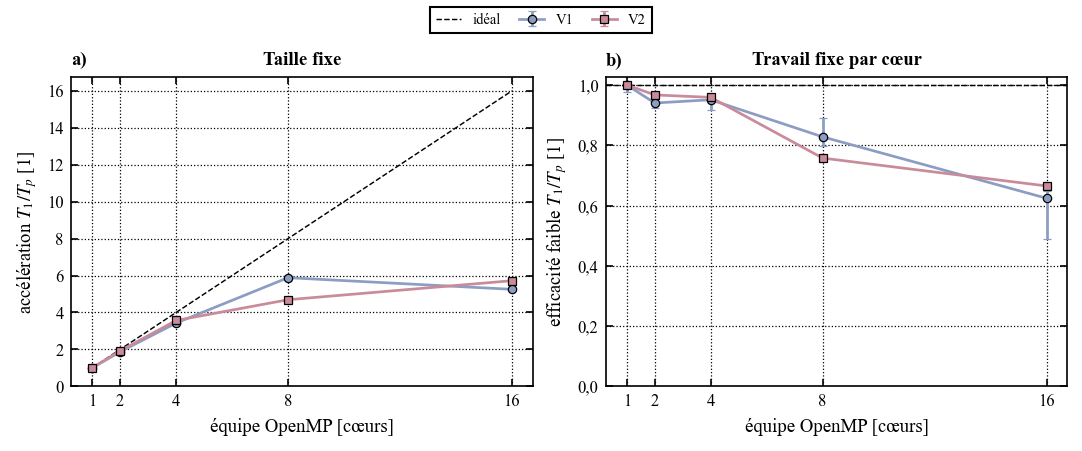

In [3]:
# Taille fixe et travail fixe par cœur, pour V1 et V2 (results/profile/cpu/scaling.csv).
sc_raw = nv_csv(PROF / "cpu/scaling.csv")
assert sc_raw.distance.eq(sc_raw.reference_distance).all()
sc_p = [1, 2, 4, 8, 16]
assert set(sc_raw.threads) == set(sc_p)
assert sc_raw.groupby(["variant", "study", "threads"]).trial.nunique().eq(3).all()
sc_fig, sc_ax = plt.subplots(1, 2, figsize=(7.1, 2.9))
for sc_i, sc_v in enumerate(["v1", "v2"]):
    sc_rows = sc_raw[sc_raw.variant.eq(sc_v)].set_index("threads")
    for sc_j, sc_study in enumerate(["strong", "weak"]):
        sc_g = sc_rows[sc_rows.study.eq(sc_study)]
        if sc_study == "strong":
            assert sc_g.input_fnv64.nunique() == 1 and sc_g.cells.eq(20000**2).all()
        else:
            assert (sc_g.cells / sc_g.index == 4096**2).all()
        sc_t1 = sc_g.loc[1, "seconds"].median()
        nv_band(sc_ax[sc_j], sc_t1 / sc_g.seconds, COLORS[sc_i], sc_v.upper(), marker="os"[sc_i])
sc_ax[0].plot(sc_p, sc_p, **GUIDE, label="idéal")
sc_ax[0].set(xlabel="équipe OpenMP [cœurs]", ylabel=r"accélération $T_1/T_p$ [1]")
sc_ax[1].axhline(1, **GUIDE, label="idéal")
sc_ax[1].set(xlabel="équipe OpenMP [cœurs]", ylabel=r"efficacité faible $T_1/T_p$ [1]")
for sc_axis in sc_ax:
    sc_axis.set_xticks(sc_p)
    sc_axis.set_ylim(bottom=0)
label_panels(sc_ax)
column_titles(sc_ax, ('Taille fixe', 'Travail fixe par cœur'))
legend_above(sc_fig, sc_ax, ncol=3)
nv_save(sc_fig, "02_echelle_cpu")

*Figure 2.* La courbe a) garde un carré de 20 000 bases de côté. La courbe b) garde 16 777 216 cases par cœur. Le point résume trois temps et les barres indiquent leurs extrêmes à temps de référence fixé.

<sub>Code : [bench/profile_cpu_driver.cpp](../bench/profile_cpu_driver.cpp), [bench/profile_cpu.py](../bench/profile_cpu.py), [bench/profile_cpu.sbatch](../bench/profile_cpu.sbatch), [results/profile/cpu/scaling.csv](../results/profile/cpu/scaling.csv).</sub>

Sur le carré de 20 000 bases, V1 passe de 164,4 ms sur un cœur à 27,9 ms sur huit, puis remonte à 31,3 ms sur seize. Son efficacité forte atteint 74 % sur huit cœurs et 33 % sur seize. À huit cœurs, NvPD met à jour les 400 millions de cases à raison de 14,3 milliards de cases par seconde (GCUPS). À travail fixe par cœur, V1 passe de 8,57 à 13,73 ms entre un et seize cœurs, soit 62,4 % d’efficacité faible. À seize cœurs, V2 atteint 66,5 % en efficacité faible.

Un million de colonnes permet d’observer cet effet sur des paires distinctes.

<p><strong><u>Synthèse.</u></strong> Le carré de 20 000 bases atteint son temps minimal sur huit cœurs parmi les cinq configurations.<br>Le passage de huit à seize cœurs allonge ensuite le temps de la boucle vectorisée d’environ 12 %.</p>

<a id="openmp-long"></a>

## Anti-diagonales et lignes de grande largeur

<hr>

La figure 3 compare deux parcours d’une même matrice sur les longues paires avec une équipe de huit cœurs.

Pour chaque FASTA, on calcule $S=T_{\rm diagonales}/T_{\rm NvPD}$ à partir d’un appel de chaque méthode. Les deux expériences utilisent la révision initiale f08b4f6. Le temps inclut la construction des tableaux et le calcul du coût après lecture du FASTA.

Le plan homogène comprend cinq paires à chaque taux, trois taux et deux méthodes. Une réplique désigne un nouveau tirage de séquences. Les six anciens témoins portant le numéro de réplique 1 restent dans les archives initiales. Les deux bibliothèques exactes vérifient toutes les distances. Une seconde campagne isole la vectorisation sur la première paire de chaque taux. Le gain du panneau b) vaut $T_{\rm initial}/T_{\rm SIMD}$. Les deux versions utilisent -O3 -march=native -fopenmp et les mêmes huit cœurs. Chaque version tourne une fois pour chaque entrée.

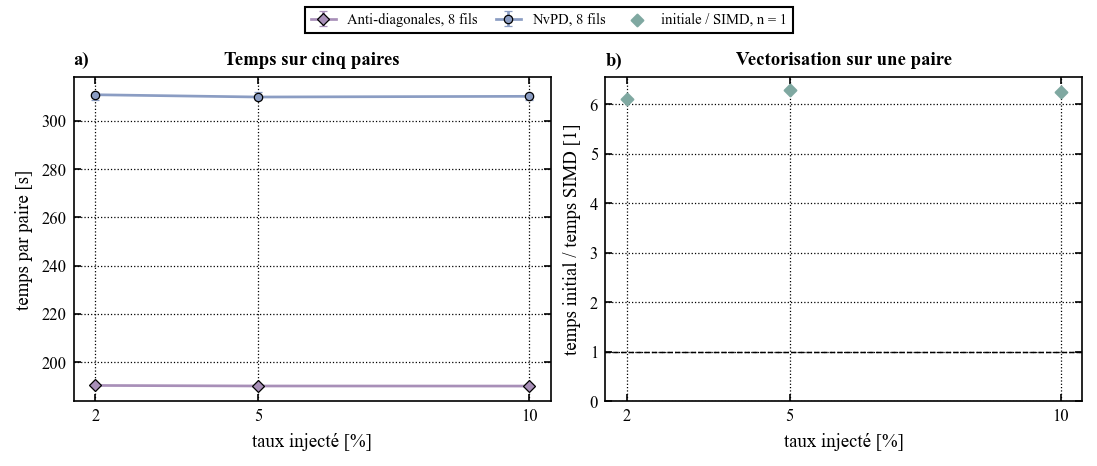

In [4]:
# Essais homogènes à un million de bases, une durée par méthode et par entrée.
long_raw = nv_csv(RES / "romeo/completion-1m/trials.csv")
assert len(long_raw) == 30 and long_raw.threads.eq(8).all() and long_raw.length.eq(1_000_000).all()
assert set(long_raw.algorithm) == {"diagonal", "nvpd-omp"}
assert long_raw.groupby(["rate", "algorithm"]).input_sha256.nunique().eq(5).all()
assert long_raw.groupby("input_sha256").distance.nunique().eq(1).all()
long_ref = nv_csv(RES / "romeo/completion-1m/references.csv")
assert set(long_ref.algorithm) == {"edlib", "wfa2"}
long_all = pd.concat([long_raw, long_ref])
assert long_all.groupby("input_sha256").algorithm.nunique().eq(4).all()
assert long_all.groupby("input_sha256").distance.nunique().eq(1).all()
long_times = long_raw.pivot(index=["rate", "input_sha256"], columns="algorithm", values="seconds")
long_ratio = long_times.diagonal / long_times["nvpd-omp"]
long_fig, long_ax = plt.subplots(1, 2, figsize=(7.2, 3.0))
for long_alg in ["diagonal", "nvpd-omp"]:
    long_series = long_times[long_alg].reset_index(level="input_sha256", drop=True)
    long_series.index = long_series.index * 100
    long_name, long_color, long_marker = nv_methods[long_alg]
    nv_band(long_ax[0], long_series, long_color, long_name, long_marker)
long_vector = nv_csv(RES / "profile/million/838538/trials.csv")
assert long_vector.groupby("rate").variant.nunique().eq(2).all() and len(long_vector)==6
long_truth = long_raw.groupby("input_sha256").distance.first()
assert long_vector.distance.eq(long_vector.input_sha256.map(long_truth)).all()
long_native = long_vector.pivot(index="rate",columns="variant",values="seconds").sort_index()
long_native_gain = long_native.initial / long_native.simd
long_ax[1].scatter(100*long_native_gain.index,long_native_gain,color=COLORS[2],marker="D",
                   label="initiale / SIMD, n = 1",zorder=3)
long_ax[1].axhline(1,**GUIDE)
long_ax[1].set_ylim(0,None)
for long_axis in long_ax:
    long_axis.set_xticks([2, 5, 10])
    long_axis.set_xlabel("taux injecté [%]")
long_ax[0].set_ylabel("temps par paire [s]")
long_ax[1].set_ylabel("temps initial / temps SIMD [1]")
label_panels(long_ax)
column_titles(long_ax, ('Temps sur cinq paires', 'Vectorisation sur une paire'))
legend_above(long_fig, long_ax, ncol=3)
nv_save(long_fig, "13_openmp_un_million")

*Figure 3.* Le panneau a) présente les temps de deux parcours denses à huit cœurs sur cinq FASTA par taux, avec médiane et extrêmes. Le panneau b) compare la boucle initiale à la boucle SIMD dans une campagne distincte, sur un FASTA par taux. Chaque point correspond à un appel par version, sans estimation de dispersion.

<sub>Code : [bench/complete_1m.sbatch](../bench/complete_1m.sbatch), [bench/collect_1m.py](../bench/collect_1m.py), [results/romeo/completion-1m/trials.csv](../results/romeo/completion-1m/trials.csv), [results/romeo/completion-1m/references.csv](../results/romeo/completion-1m/references.csv), [results/profile/million/838538/trials.csv](../results/profile/million/838538/trials.csv).</sub>

À 2 %, les médianes sur cinq paires valent 190,3 s pour les anti-diagonales et 310,9 s pour NvPD. À 10 %, elles atteignent 190,0 et 310,3 s. Chaque valeur du graphique provient d’un alignement dont la distance concorde avec les deux bibliothèques. La compilation native d’architecture du panneau b) prend, dans l’ordre des taux, 324,4, 326,4, 322,4 s avec la boucle initiale et 53,0, 51,9, 51,6 s avec la boucle SIMD.

La réécriture de la boucle de NvPD permet ensuite d’isoler le rôle du compilateur.

<p><strong><u>Synthèse.</u></strong> À 5 % d’erreur, le rapport médian entre les temps anti-diagonales et NvPD vaut 0,61 sur huit cœurs.<br>Les anti-diagonales terminent avant la version historique de NvPD aux trois taux mesurés.</p>

<a id="vectorisation"></a>

## Vectorisation de la récurrence de dernière occurrence

<hr>

La figure 4 isole les gains successifs de la vectorisation de la récurrence et de la compression de son index.

La version initiale utilise la dernière occurrence $k$ d’une lettre pour choisir le prédécesseur. Pour la case $(i,j)$, $k$ est la dernière position de la lettre $a_i$ dans $b_1,\dots,b_j$ et vaut zéro si elle est absente. Sur les colonnes intérieures, V1 calcule

$$D_{i,j}=\min\!\left(1+\min(D_{i-1,j-1},D_{i-1,j}),\,D_{i-1,\max(0,k-1)}+j-k\right).$$

Les bords valent $D_{i,0}=i$ et $D_{0,j}=j$. La formule lit uniquement la ligne précédente. Quand $k=j$, le second candidat reprend la diagonale sans coût. Quand $k=0$, il vaut $i-1+j$, une borne supérieure de la distance. Cette forme permet à OpenMP de vectoriser les colonnes. V2 reprend cette boucle et stocke les écarts $j-k$ sur un octet lorsque le maximum reste inférieur à 256. Si un écart est plus grand, V2 garde les entiers de quatre octets. Les scores restent entiers dans les trois versions. Les appels NvPD incluent la construction de l’index de dernières occurrences, l’allocation et les mises à jour de la matrice. Chaque paire de variantes utilise la même compilation, avec `-O3 -march=native -fopenmp`. À chaque répétition, le pilote mélange l’ordre des cas et alterne A puis B ou B puis A.

Les trois géométries isolent deux effets. Le carré de 20 000 × 20 000 distribue de nombreuses lignes de taille modérée. Les rectangles de 256 × 1 000 000 et de 64 × 4 194 304 contiennent des lignes de plus en plus longues et peu de barrières. Le second rectangle donne à l’index une largeur de plus de quatre millions de colonnes pour étudier son comportement dans les caches.

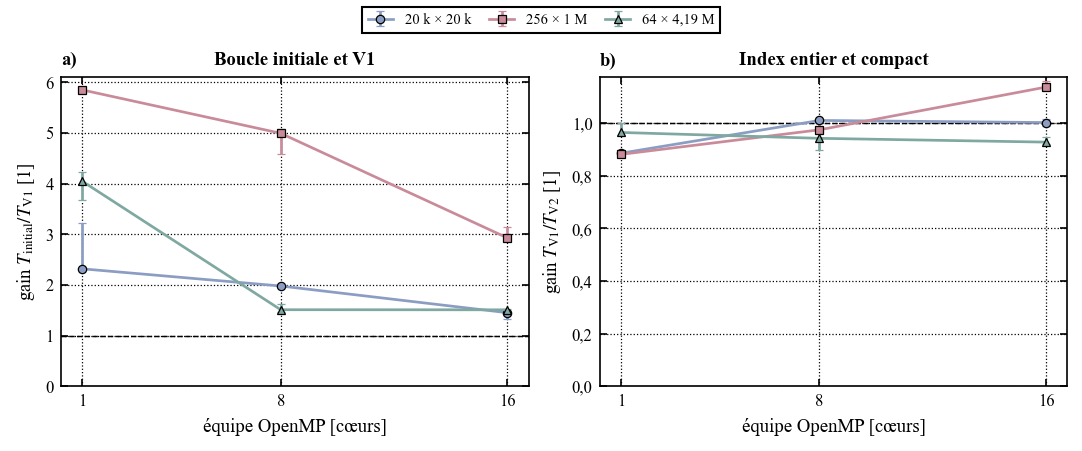

In [5]:
# Gains par étape à entrées et placement identiques (results/profile/cpu/ab.csv).
ab_raw = nv_csv(PROF / "cpu/ab.csv")
assert ab_raw.distance.eq(ab_raw.reference_distance).all()
assert ab_raw.groupby("case").input_fnv64.nunique().eq(1).all()
assert ab_raw.groupby(["comparison", "case", "threads", "trial"]).cpu_ids.nunique().eq(1).all()
assert ab_raw.groupby("case").max_gap.max().lt(256).all()
ab_cases = {"square": "20 k × 20 k", "wide": "256 × 1 M", "over_l3": "64 × 4,19 M"}
# Expérience distincte, une paire de mesures par taux à un million de bases.
ab_long = nv_csv(RES / "profile/million/838538/trials.csv")
assert len(ab_long)==6 and set(ab_long.variant)=={"initial","simd"}
assert ab_long.groupby("rate").input_sha256.nunique().eq(1).all()
assert ab_long.groupby("rate").distance.nunique().eq(1).all()
assert ab_long.groupby("rate").cpu_ids.nunique().eq(1).all()
ab_long_ref = nv_pair[nv_pair.algorithm.eq("edlib") & nv_pair.rep.eq(1) & nv_pair.length.eq(1_000_000)].set_index("input_sha256").distance
assert ab_long.distance.eq(ab_long.input_sha256.map(ab_long_ref)).all()
ab_long_seconds = ab_long.pivot(index="rate",columns="variant",values="seconds")
ab_long_gains = ab_long_seconds.initial / ab_long_seconds.simd

ab_fig, ab_ax = plt.subplots(1, 2, figsize=(7.1, 2.9))
for ab_i, (ab_a, ab_b) in enumerate([("baseline", "v1"), ("v1", "v2")]):
    ab_sub = ab_raw[ab_raw.comparison.eq(ab_a + "-" + ab_b)]
    ab_time = ab_sub.pivot(index=["case", "threads", "trial"], columns="variant", values="seconds")
    assert ab_time.notna().all().all() and (ab_time > 0).all().all()
    ab_rat = ab_time[ab_a] / ab_time[ab_b]
    for ab_k, (ab_case, ab_name) in enumerate(ab_cases.items()):
        nv_band(ab_ax[ab_i], ab_rat.xs(ab_case).droplevel("trial"), COLORS[ab_k], ab_name, marker="os^"[ab_k])
    ab_ax[ab_i].axhline(1, **GUIDE)
    ab_ax[ab_i].set(xlabel="équipe OpenMP [cœurs]", ylim=(0, None))
    ab_ax[ab_i].set_xticks([1, 8, 16])
ab_ax[0].set_ylabel(r"gain $T_\mathrm{initial}/T_\mathrm{V1}$ [1]")
ab_ax[1].set_ylabel(r"gain $T_\mathrm{V1}/T_\mathrm{V2}$ [1]")
label_panels(ab_ax)
column_titles(ab_ax, ('Boucle initiale et V1', 'Index entier et compact'))
legend_above(ab_fig, ab_ax, ncol=3)
nv_save(ab_fig, "03_variantes_cpu")

*Figure 4.* Les rapports comparent la boucle vectorisée à la boucle initiale en a), puis l’index compact à l’index entier en b). Les points et les barres donnent la médiane et les extrêmes des trois gains appariés.

<sub>Code : [src/dp.cpp](../src/dp.cpp), [bench/profile_cpu.md](../bench/profile_cpu.md), [bench/profile_cpu.py](../bench/profile_cpu.py), [results/profile/cpu/ab.csv](../results/profile/cpu/ab.csv), [results/profile/million/838538/trials.csv](../results/profile/million/838538/trials.csv).</sub>

Sur le carré, V1 réduit le temps d’un facteur 2,32 à un cœur, 1,98 à huit et 1,45 à seize. Pour le rectangle de 256 lignes, le gain atteint 5,85 à un cœur. Le gain apparié de V2 par rapport à V1 atteint 1,14 sur ce rectangle à seize cœurs, puis tombe à 0,93 sur le rectangle de 64 lignes. Sur le carré à un cœur, il vaut 0,89.

Le panneau b) de la figure 3 reprend les paires d’un million de bases du job 838538. À 2 %, 5 % et 10 %, les rapports initiale/SIMD sont respectivement 6,116, 6,289, 6,246. Les trois groupes travaillent en parallèle sur 24 cœurs disjoints. Chaque version passe une fois sur chaque paire, sans chauffe complète.

Les compteurs de cache permettent de comparer les lectures avec les tailles allouées.

<p><strong><u>Synthèse.</u></strong> La boucle vectorisée avec un index entier accélère les 9 configurations mesurées.<br>L’index compact bénéficie à certaines longues lignes, au prix d’un temps de conversion.</p>

<a id="hierarchie-memoire"></a>

## Occupation mémoire et défauts du cache de données

<hr>

La figure 5 compare l’espace occupé par les tableaux et le nombre de défauts de lecture L1D selon la largeur de la matrice.

Pour un alphabet de quatre lettres, les deux lignes de scores occupent $2(n+1)$ entiers. L’index des dernières occurrences en occupe $4(n+1)$. V1 occupe donc $24(n+1)$ octets. Si la conversion réussit, V2 occupe $12(n+1)$ octets pendant la boucle. La conversion conserve temporairement deux représentations de l’index. Une ligne lue pour une lettre donnée ne consulte qu’une des quatre lignes de cet index. Le pic RSS mesure le maximum de mémoire résidente du processus entier, y compris les chaînes, les autres allocations et la phase de chauffe.

Les compteurs en espace utilisateur couvrent un appel après chauffe, pour toute l’équipe OpenMP. Le pilote ouvre et ferme la fenêtre de mesure avec `perf stat --control`. Un compteur non pris en charge représente une mesure manquante. Les événements génériques dépendent du PMU et ne suffisent pas à déduire un débit DRAM. Les écarts maximaux, de 31 à 48 selon la forme, permettent à V2 d’utiliser des octets sur les trois cas. [Linux perf, manuel de perf-stat](https://man7.org/linux/man-pages/man1/perf-stat.1.html)

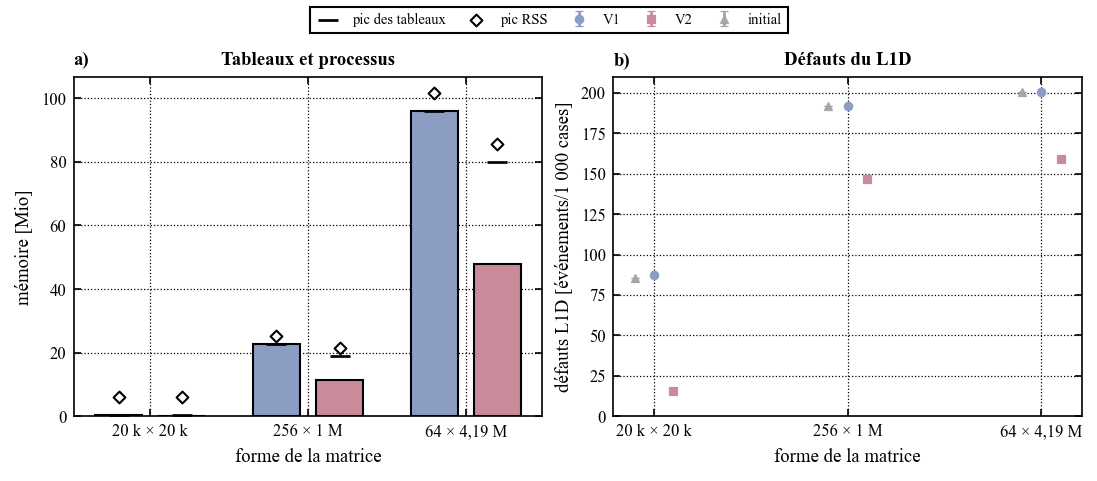

In [6]:
# Espace de travail et événements L1D, huit cœurs (results/profile/cpu/{ab,counters}.csv).
me_perf = nv_csv(PROF / "cpu/counters.csv")
assert me_perf.distance.eq(me_perf.reference_distance).all()
assert me_perf.running_pct.eq(100).all()
me_perf["event"] = me_perf.event.str.removesuffix(":u")
me_perf["count"] = pd.to_numeric(me_perf.value, errors="coerce")
me_perf["per_cell"] = me_perf["count"] / (me_perf.m * me_perf.n)
me_fig, me_ax = plt.subplots(1, 2, figsize=(7.2, 3.1))
me_x = np.arange(len(ab_cases))
me_rows = ab_raw[(ab_raw.threads == 8) & ab_raw.comparison.eq("v1-v2")]
for me_i, me_v in enumerate(["v1", "v2"]):
    me_g = me_rows[me_rows.variant.eq(me_v)].groupby("case")
    me_scores = me_g.dp_bytes.first().reindex(ab_cases)
    me_index = me_g.mit_bytes.first().reindex(ab_cases)
    me_peak = me_g.workspace_peak_bytes.first().reindex(ab_cases)
    me_rss = me_g.peak_rss_kib.max().reindex(ab_cases) / 1024
    me_pos = me_x + .2 * (2*me_i - 1)
    me_ax[0].bar(me_pos, (me_scores + me_index) / 2**20, width=.30, color=COLORS[me_i],
                 edgecolor=INK, label=me_v.upper(), zorder=2)
    me_ax[0].scatter(me_pos, me_peak / 2**20, marker="_", s=100, color=INK,
                     zorder=3, label="pic des tableaux" if me_i == 0 else None)
    me_ax[0].scatter(me_pos, me_rss, marker="D", s=16, facecolor=PAPER, edgecolor=INK,
                     zorder=3, label="pic RSS" if me_i == 0 else None)
for me_k, me_v in enumerate(["baseline", "v1", "v2"]):
    me_g = me_perf[(me_perf.threads == 8) & me_perf.event.eq("L1-dcache-load-misses") & me_perf.variant.eq(me_v)]
    me_vals = me_g.groupby("case").per_cell.agg(["median", "min", "max"]).reindex(ab_cases) * 1000
    me_ax[1].errorbar(me_x + .1*(me_k-1), me_vals["median"], fmt=["^", "o", "s"][me_k],
                      color=[COLORS[4], COLORS[0], COLORS[1]][me_k], capsize=2,
                      yerr=[me_vals["median"]-me_vals["min"], me_vals["max"]-me_vals["median"]],
                      label=me_v.upper() if me_v != "baseline" else "initial")
me_ax[0].set(ylabel="mémoire [Mio]", xlabel="forme de la matrice")
me_ax[1].set(ylabel="défauts L1D [événements/1 000 cases]", xlabel="forme de la matrice", ylim=(0, None))
for me_axis in me_ax:
    me_axis.set_xticks(me_x, ab_cases.values())
label_panels(me_ax)
column_titles(me_ax, ('Tableaux et processus', 'Défauts du L1D'))
legend_above(me_fig, me_ax, ncol=5)
nv_save(me_fig, "04_memoire_cpu")

*Figure 5.* Les barres du panneau a) représentent les tableaux actifs à huit cœurs. Le tiret indique leur maximum pendant l’appel et le losange le pic de RSS du processus. Le panneau b) rapporte les défauts L1D à 1 000 cases lors de deux appels après chauffe.

<sub>Code : [bench/profile_cpu_driver.cpp](../bench/profile_cpu_driver.cpp), [bench/profile_cpu.py](../bench/profile_cpu.py), [results/profile/cpu/environment.txt](../results/profile/cpu/environment.txt), [results/profile/cpu/counters.csv](../results/profile/cpu/counters.csv).</sub>

La conversion atteint 80 Mio et le processus monte à 85,5 Mio, contre 101,6 Mio en V1. Sur huit cœurs, on compte 159 défauts L1D pour 1 000 cases en V2, contre 200 en V1, alors que le rapport de temps V1/V2 vaut 0,94. Le nœud dispose de 32 Kio de L1D et 1 Mio de L2 par cœur, ainsi que de blocs de 32 Mio de L3 partagés par huit cœurs. Le plus grand index dépasse la capacité d’un de ces blocs.

Le nombre d’instructions par case renseigne sur les autres coûts de la boucle.

<p><strong><u>Synthèse.</u></strong> Sur le rectangle de 4 194 304 colonnes, l’index compact ramène les tableaux actifs de 96 à 48 Mio.<br>Les compteurs L1D décrivent les lectures du cache. Ils ne donnent pas le débit du contrôleur DRAM.</p>

<a id="trace-lineaire"></a>

## Reconstruction de l’alignement en espace linéaire

<hr>

La figure 6 compare le temps et le pic de mémoire du processus pour retrouver un chemin optimal de deux manières.

Le procédé de Hirschberg a été publié pour la plus longue sous-séquence commune. Ici les deux passes utilisent les coûts de Levenshtein. À la coupure $i=\lfloor m/2\rfloor$, $F_j$ donne le coût entre les préfixes $a_{1:i}$ et $b_{1:j}$. Une passe sur les chaînes inversées donne les coûts de suffixe $R_{n-j}$. On choisit $j^\star\in\arg\min_j(F_j+R_{n-j})$ et on reconstruit les deux sous-chemins. Les passes calculent au total $O(mn)$ cases et utilisent $O(\min(m,n))$ scores en choisissant la chaîne la plus courte pour les colonnes. Cette borne exclut le CIGAR en sortie et la pile de récursion. [Hirschberg, 1975](https://doi.org/10.1145/360825.360861)

Les mesures locales sur Apple M1 Pro lancent les algorithmes sur le même FASTA lorsqu’ils acceptent sa longueur. La compilation Release utilise Apple Clang 21 et un seul fil. Chaque configuration est répétée dans cinq processus neufs. Le pilote rejoue les 25 CIGAR et compare le score avec edlib. Les cases de la figure représentent les configurations exécutées. L’implémentation qui conserve tout le tableau limite les deux longueurs à 20 000 bases pour le chemin.

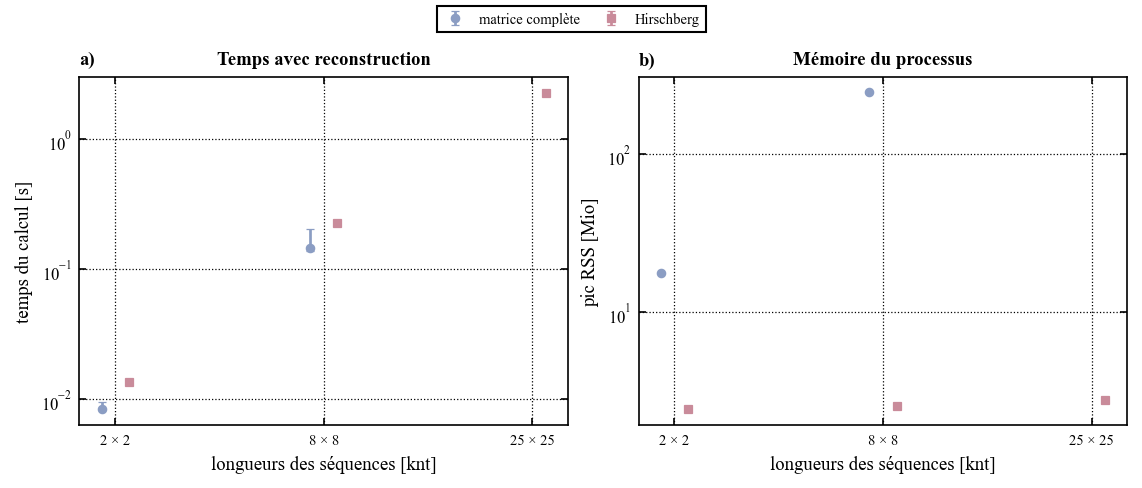

In [7]:
# Coût et mémoire d'une reconstruction complète ou par coupures.
tb_raw = nv_csv(RES / "traceback/trials.csv")
assert tb_raw.groupby(["case","algorithm"]).trial.nunique().eq(5).all() and len(tb_raw)==25
assert tb_raw.groupby("case").distance.nunique().eq(1).all() and tb_raw.groupby("case").sha256.nunique().eq(1).all()
tb_shapes = tb_raw[["case","m","n"]].drop_duplicates().sort_values(["m","n"]).set_index("case")
tb_cases = list(tb_shapes.index)
tb_labels = [f"{tb_shapes.loc[c,'m']/1000:g} × {tb_shapes.loc[c,'n']/1000:g}" for c in tb_cases]
tb_alg_h = next(method for method in tb_raw.algorithm.unique() if "hirsch" in method.lower())
tb_alg_d = next(method for method in tb_raw.algorithm.unique() if method!=tb_alg_h)
tb_fig, tb_ax = plt.subplots(1,2,figsize=(7.5,3.15))
tb_x = np.arange(len(tb_cases))
for tb_ix,(tb_alg,tb_title) in enumerate([(tb_alg_d,"matrice complète"),(tb_alg_h,"Hirschberg")]):
    tb_group = tb_raw[tb_raw.algorithm.eq(tb_alg)].groupby("case")
    for tb_axis,tb_metric,tb_factor in [(tb_ax[0],"seconds",1),(tb_ax[1],"peak_rss_kib",1/1024)]:
        tb_vals = tb_group[tb_metric].agg(["min","median","max"]).reindex(tb_cases)*tb_factor
        tb_mask=tb_vals["median"].notna()
        tb_axis.errorbar(tb_x[tb_mask]+(tb_ix-.5)*.13,tb_vals.loc[tb_mask,"median"],
                        yerr=[tb_vals.loc[tb_mask,"median"]-tb_vals.loc[tb_mask,"min"],tb_vals.loc[tb_mask,"max"]-tb_vals.loc[tb_mask,"median"]],
                        fmt="os"[tb_ix],color=COLORS[tb_ix],label=tb_title,capsize=2)
for tb_axis in tb_ax:
    tb_axis.set_xticks(tb_x,tb_labels,fontsize=7)
    tb_axis.set_xlabel("longueurs des séquences [knt]")
    tb_axis.set_yscale("log")
tb_ax[0].set_ylabel("temps du calcul [s]")
tb_ax[1].set_ylabel("pic RSS [Mio]")
label_panels(tb_ax)
column_titles(tb_ax, ('Temps avec reconstruction', 'Mémoire du processus'))
legend_above(tb_fig,tb_ax,ncol=2)
nv_save(tb_fig, "21_trace_lineaire")

*Figure 6.* La durée en a) et le RSS en b) couvrent le calcul avec reconstruction. Les points résument les répétitions d’une méthode pour la même paire et les barres donnent les extrêmes. Une méthode absente sur une paire n’a aucune valeur tracée.

<sub>Code : [src/hirschberg.cpp](../src/hirschberg.cpp), [bench/traceback.py](../bench/traceback.py), [results/traceback/trials.csv](../results/traceback/trials.csv).</sub>

Sur 8000 × 8000 bases, la matrice complète demande 0,146 s et la reconstruction par coupures 0,226 s. Le pic RSS médian passe de 246,7 Mio avec la matrice à 2,5 Mio avec les coupures. Au-delà de 20 000 bases, la reconstruction par coupures donne une distance de 531 pour une paire de 25000 × 25000 bases. Sa durée médiane vaut 2,253 s et le pic RSS médian atteint 2,80 Mio.

Les compteurs du processeur permettent ensuite d’examiner les instructions du calcul de coût.

<p><strong><u>Synthèse.</u></strong> À 8 000 bases par séquence, la méthode de Hirschberg divise le pic RSS du processus par environ 97.<br>Les passes de reconstruction augmentent le temps de calcul sur cette paire.</p>

<a id="instructions"></a>

## Instructions et prédictions de branchement

<hr>

La figure 7 rapporte le travail exécuté par le processeur au nombre de cases de la matrice.

Pour $N=mn$ cases, les événements par case valent $C/N$. Les compteurs proviennent de deux appels après chauffe et la fréquence d’horloge peut varier.

L’IPC rapporte les instructions retirées aux cycles comptés. Un événement de branchement mal prédit concerne le chemin d’exécution du processeur. Sur une équipe, les cycles comptés s’additionnent sur les fils. Les données de cette figure proviennent d’un seul cœur.

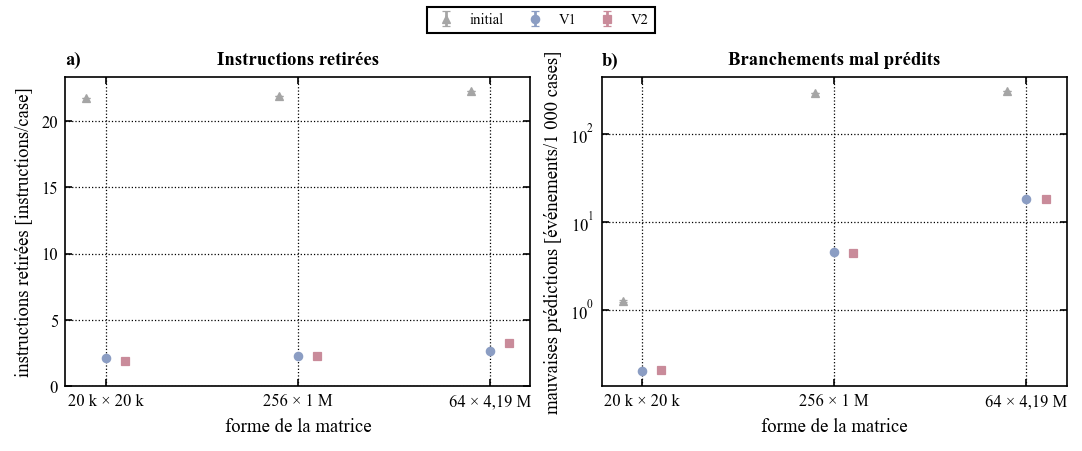

In [8]:
# Compteurs du calcul à un cœur. La valeur disponible est ramenée à une case.
pm_g = me_perf[me_perf.threads.eq(1)]
pm_fig, pm_ax = plt.subplots(1, 2, figsize=(7.1, 2.9))
pm_events = [("instructions", 1, "instructions retirées [instructions/case]"),
             ("branch-misses", 1000, "mauvaises prédictions [événements/1 000 cases]")]
for pm_j, (pm_event, pm_scale, pm_title) in enumerate(pm_events):
    for pm_i, (pm_v, pm_label) in enumerate([("baseline", "initial"), ("v1", "V1"), ("v2", "V2")]):
        pm_sub = pm_g[pm_g.event.eq(pm_event) & pm_g.variant.eq(pm_v)]
        pm_val = pm_sub.groupby("case").per_cell.agg(["median", "min", "max"]).reindex(ab_cases) * pm_scale
        pm_ax[pm_j].errorbar(me_x + .1*(pm_i-1), pm_val["median"], fmt=["^", "o", "s"][pm_i],
                             color=[COLORS[4], COLORS[0], COLORS[1]][pm_i], capsize=2,
                             yerr=[pm_val["median"]-pm_val["min"], pm_val["max"]-pm_val["median"]],
                             label=pm_label)
    pm_ax[pm_j].set_xticks(me_x, ab_cases.values())
    pm_ax[pm_j].set(xlabel="forme de la matrice", ylabel=pm_title)
    if pm_j == 1:
        pm_ax[pm_j].set_yscale("log")
    else:
        pm_ax[pm_j].set_ylim(bottom=0)
label_panels(pm_ax)
column_titles(pm_ax, ('Instructions retirées', 'Branchements mal prédits'))
legend_above(pm_fig, pm_ax, ncol=3)
nv_save(pm_fig, "05_cout_instructions")

*Figure 7.* Les mesures sur un cœur rapportent les instructions retirées à une case en a) et les mauvaises prédictions à 1 000 cases en b). Chaque intervalle relie les résultats de deux appels après chauffe.

<sub>Code : [src/dp.cpp](../src/dp.cpp), [bench/profile_cpu.py](../bench/profile_cpu.py), [results/profile/cpu/vectorization.csv](../results/profile/cpu/vectorization.csv), [results/profile/cpu/counters.csv](../results/profile/cpu/counters.csv).</sub>

À un cœur sur le rectangle de 256 lignes, les instructions passent de 21,89 par case à 2,26 entre la version initiale et V1. Les mauvaises prédictions passent de 291 à 4,5 pour 1 000 cases et les cycles de 9,46 à 1,59 par case. Pour le carré, les mauvaises prédictions sont déjà rares dans la version initiale (1,3 pour 1 000 cases) et V1 réduit encore le nombre d’instructions de 21,76 à 2,13 par case. Le diagnostic de GCC confirme des vecteurs de 32 octets dans cette boucle.

Sur GPU, la même indépendance entre colonnes permet de regrouper plusieurs lignes.

<p><strong><u>Synthèse.</u></strong> Sur le grand rectangle à un cœur, la version vectorisée réduit les cycles par case d’un facteur 5,95.<br>Le coût de la prédiction se manifeste davantage sur ce rectangle que sur le carré.</p>

<a id="tuiles-cuda"></a>

## Regroupement des lignes en tuiles CUDA

<hr>

La figure 8 compare un noyau CUDA lancé à chaque ligne à un noyau qui regroupe plusieurs lignes.

Pour $q$ lignes par tuile et $m$ lignes, le noyau principal est lancé $\lceil m/q\rceil$ fois si la portée des dépendances permet ce découpage. Le gain vaut le rapport des médianes par processus. Chaque médiane chaude résume trois appels.

Dans la version initiale (A), le CPU lance un noyau par ligne. La variante retenue (B) avance de huit lignes par tuile en mémoire partagée. Chaque bloc recalcule un halo à gauche pour pouvoir progresser sans lire le travail d’un bloc voisin. Ses 256 fils couvrent 1 024 colonnes lorsque la grille garde au moins deux blocs par multiprocesseur, sinon 256. Lorsque la dépendance gauche dépasse 64 colonnes, ou que le chemin d’alignement est demandé, le programme utilise le noyau par ligne. La mesure à froid démarre dans un processus neuf. Les mesures à chaud démarrent après un premier appel vérifié dans ce même processus. Le retour du dernier coût sur l’hôte garantit que le GPU a terminé. Dans les deux cas, le temps couvre aussi le calcul de l’index, les allocations et les transferts. [NVIDIA, mesure du temps CPU et GPU](https://docs.nvidia.com/cuda/cuda-c-best-practices-guide/index.html#timing)

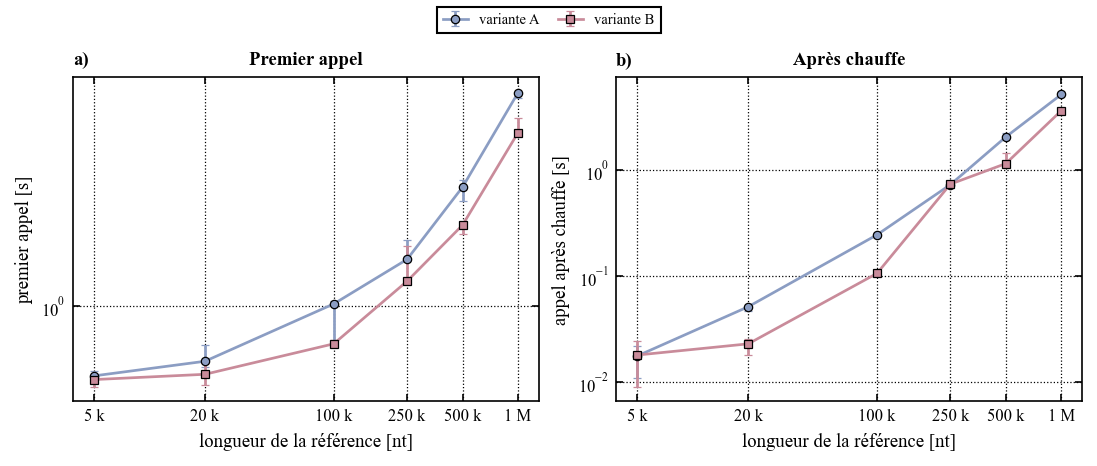

In [9]:
# Appels froids et chauds sur les mêmes FASTA, hors capture Nsight.
gp_dir = PROF / "gpu/838170"
gp_raw = nv_csv(gp_dir / "trials.csv")
gp_truth = nv_pair[nv_pair.algorithm.eq("edlib") & nv_pair.rate.eq(.02) & nv_pair.rep.eq(1)]
assert set(gp_raw.variant) == {"baseline", "candidate"} and gp_raw.trace.eq(0).all()
gp_ref = gp_truth.set_index("length").distance
assert gp_raw.groupby("input").distance.nunique().eq(1).all()
gp_comparable = gp_raw[gp_raw.m.isin(gp_ref.index)]
assert gp_comparable.distance.eq(gp_comparable.m.map(gp_ref)).all()
assert gp_raw.groupby(["input", "variant", "mode"]).run.nunique().eq(3).all()
gp_counts = gp_raw.groupby(["input", "variant", "mode", "run"]).size()
assert gp_counts.xs("cold", level="mode").eq(1).all() and gp_counts.xs("warm", level="mode").eq(3).all()
assert gp_raw.groupby("input").device_bytes.nunique().eq(1).all()
gp_hold = nv_csv(PROF / "gpu/838173/trials.csv")
gp_htruth = nv_pair[nv_pair.algorithm.eq("edlib") & nv_pair.rate.eq(.10) & nv_pair.rep.eq(1)]
assert gp_hold.distance.eq(gp_hold.m.map(gp_htruth.set_index("length").distance)).all()
gp_groups = ["m", "variant", "mode", "run"]
# Une mesure froide et une médiane des mesures chaudes par processus.
gp_lineage = pd.concat({"tuiles fixes, 2 %": nv_csv(PROF / "gpu/838161/trials.csv"),
                        "largeur adaptative, 2 %": gp_raw, "largeur adaptative, 10 %": gp_hold},
                       names=["expérience"]).reset_index(level=0)
gp_runs = gp_lineage.groupby(["expérience", *gp_groups], as_index=False).seconds.median()
gp_medians = gp_runs.groupby(["expérience", "m", "mode", "variant"]).seconds.median().unstack()
gp_medians["gain"] = gp_medians["baseline"] / gp_medians["candidate"]
gp_run = gp_runs[gp_runs["expérience"].eq("largeur adaptative, 2 %")]
gp_fig, gp_ax = plt.subplots(1, 2, figsize=(7.2, 3.0))
for gp_k, (gp_variant, gp_label) in enumerate([("baseline", "A"), ("candidate", "B")]):
    for gp_i, gp_mode in enumerate(["cold", "warm"]):
        gp_sub = gp_run[gp_run.variant.eq(gp_variant) & gp_run["mode"].eq(gp_mode)].set_index("m")
        nv_band(gp_ax[gp_i], gp_sub.seconds, COLORS[gp_k], "variante " + gp_label, marker="os"[gp_k])
for gp_axis, gp_label in zip(gp_ax, ["premier appel [s]", "appel après chauffe [s]"]):
    gp_axis.set(xscale="log", yscale="log", xlabel="longueur de la référence [nt]", ylabel=gp_label)
    gp_sizes = np.sort(gp_run.m.unique())
    gp_ticks = {5000: "5 k", 20000: "20 k", 100000: "100 k", 250000: "250 k", 500000: "500 k", 1000000: "1 M"}
    gp_axis.set_xticks(gp_sizes, [gp_ticks[v] for v in gp_sizes])
label_panels(gp_ax)
column_titles(gp_ax, ('Premier appel', 'Après chauffe'))
legend_above(gp_fig, gp_ax, ncol=2)
nv_save(gp_fig, "06_variantes_gpu")

*Figure 8.* Les temps correspondent à la première paire de chaque longueur à 2 % d’erreur. Le panneau a) montre le premier appel de chaque processus. Le panneau b) résume trois appels chauds par processus. Les points et les barres donnent la médiane et les extrêmes des trois processus.

<sub>Code : [src/cuda.cu](../src/cuda.cu), [bench/profile_gpu.cu](../bench/profile_gpu.cu), [results/profile/gpu/838170/trials.csv](../results/profile/gpu/838170/trials.csv).</sub>

Le premier essai de tuiles fixes (job 838161) donnait 2,70× de gain à chaud sur 5 000 bases et 0,98× sur un million. Dans le job 838170, la largeur adaptative ramène le temps chaud à un million de 5,14 à 3,62 s (1,42×). À froid, les temps passent de 5,85 à 4,20 s (1,39×). Dans le contrôle indépendant à 10 % (job 838173), les gains à chaud valent 2,42×, 3,22× et 2,38× à 5, 20 et 100 milliers de bases. À un million, le temps passe de 5,15 à 3,64 s (1,41×). Le même gain à chaud dans le job 838170 vaut 2,24× à 20 000 et 1,78× à 500 000 bases. Les tampons globaux explicitement alloués valent 22,9 Mio à un million pour les deux versions. Ce total exclut la mémoire partagée par bloc et le contexte CUDA.

La trace d’un appel court permet de compter les lancements et de séparer leurs durées.

<p><strong><u>Synthèse.</u></strong> À 2 % d’erreur, les gains chauds à 5 000 et 250 000 bases valent 0,98 et 0,99.<br>La largeur adaptative donne un gain supérieur à un sur les quatre autres tailles.</p>

<a id="trace-cuda"></a>

## Chronologie des appels hôte et des noyaux CUDA

<hr>

La figure 9 décompose une trace CUDA pour associer le nombre de lancements aux durées hôte et GPU.

Le temps cumulé des noyaux vaut $T_K=\sum_i t_i$. Les domaines hôte et GPU peuvent se recouvrir. La mesure A/B du temps mural provient d’exécutions séparées.

Nsight Systems encadre un appel après chauffe sur la paire de 5 000 bases à 2 %. Le nombre de noyaux correspond aux instances enregistrées. Les temps d’API hôte incluent les appels de lancement. Les temps GPU proviennent des noyaux et des transferts. [NVIDIA, profilage d’une fenêtre d’exécution](https://docs.nvidia.com/nsight-systems/UserGuide/index.html#focused-profiling)

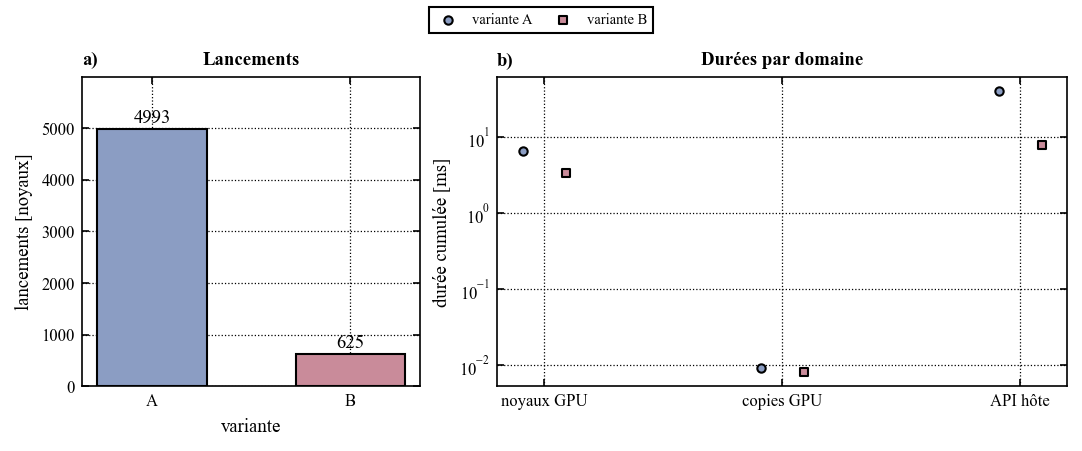

In [10]:
# Comptage des noyaux et temps par domaine de mesure (exports Nsight du job GPU).
ns_rows = []
for ns_variant in ("baseline", "candidate"):
    ns_k = nv_csv(gp_dir / f"{ns_variant}_cuda_gpu_kern_sum.csv")
    ns_a = nv_csv(gp_dir / f"{ns_variant}_cuda_api_sum.csv")
    ns_t = nv_csv(gp_dir / f"{ns_variant}_cuda_gpu_mem_time_sum.csv")
    ns_rows.append({"variante": ns_variant, "noyaux": ns_k.Instances.sum(),
                    "noyaux GPU": ns_k["Total Time (ns)"].sum() / 1e6,
                    "copies GPU": ns_t["Total Time (ns)"].sum() / 1e6,
                    "API hôte": ns_a["Total Time (ns)"].sum() / 1e6})
ns_tot = pd.DataFrame(ns_rows).set_index("variante")
ns_fig, ns_ax = plt.subplots(1, 2, figsize=(7.1, 2.9), width_ratios=[.8, 1.35])
ns_colors = COLORS[:2]
ns_x = np.arange(3)
for ns_i, (ns_variant, ns_label) in enumerate([("baseline", "A"), ("candidate", "B")]):
    ns_count = int(ns_tot.loc[ns_variant, "noyaux"])
    ns_ax[0].bar(ns_i, ns_count, width=.55, color=ns_colors[ns_i], edgecolor=INK)
    ns_ax[0].annotate(str(ns_count), (ns_i, ns_count), xytext=(0, 3), textcoords="offset points", ha="center")
    ns_vals = ns_tot.loc[ns_variant, ["noyaux GPU", "copies GPU", "API hôte"]]
    ns_ax[1].scatter(ns_x + (ns_i - .5) * .18, ns_vals, color=ns_colors[ns_i], marker="os"[ns_i],
                     edgecolor=INK, label="variante " + ns_label, zorder=3)
ns_ax[0].set_xticks([0, 1], ["A", "B"])
ns_ax[0].set(ylabel="lancements [noyaux]", xlabel="variante", ylim=(0, ns_tot.noyaux.max()*1.2))
ns_ax[1].set_xticks(ns_x, ["noyaux GPU", "copies GPU", "API hôte"])
ns_ax[1].set(yscale="log", ylabel="durée cumulée [ms]")
label_panels(ns_ax)
column_titles(ns_ax, ('Lancements', 'Durées par domaine'))
legend_above(ns_fig, ns_ax, ncol=2)
nv_save(ns_fig, "07_trace_cuda")

*Figure 9.* La capture d’un appel chaud sur 5 000 × 4 992 bases compte les noyaux en a) et cumule les durées en b). La somme des durées hôte et GPU comprend des périodes qui se chevauchent.

<sub>Code : [bench/profile_gpu.sbatch](../bench/profile_gpu.sbatch), [results/profile/gpu/838170](../results/profile/gpu/838170/).</sub>

Sur cette paire, A lance un noyau d’initialisation et 4 992 noyaux de ligne. B lance le même noyau d’initialisation et 624 noyaux de tuile. Le temps cumulé des noyaux passe de 6,46 à 3,34 ms, celui des appels hôtes à `cudaLaunchKernel` de 12,21 à 1,53 ms. Les copies sur le GPU totalisent environ 9 et 8 µs. La capture ralentit elle-même certains appels et ne permet pas de prévoir à elle seule le rapport de temps de bout en bout de la figure 8.

La variation de l’ordre de lecture offre une autre observation de la hiérarchie mémoire.

<p><strong><u>Synthèse.</u></strong> Les appels hôte à cudaLaunchKernel prennent au total environ 8 fois moins de temps avec les tuiles.<br>La capture ne donne aucun taux de défaut du cache GPU, les compteurs matériels étant restreints.</p>

<a id="localite-gpu"></a>

## Localité des lectures en mémoire globale

<hr>

La figure 10 compare le regroupement des adresses des warps entre les noyaux par ligne et la politique de tuiles.

Pour les adresses en octets $a_t$ des fils actifs d’un warp, le modèle compte $N_s=|\{\lfloor a_t/32\rfloor\}|$ secteurs de 32 octets par instruction logique. Le modèle suppose le découpage des adresses fourni par les noyaux. Il ne connaît ni les résidences en cache ni les transactions HBM.

La sonde rejoue les accès des warps à l’index, à la diagonale, au prédécesseur vertical, au prédécesseur de dernière occurrence et aux écritures globales. La somme des octets des secteurs divisée par le nombre de cases mesure les demandes logiques. La fraction utile compte les mots distincts de quatre octets dans chaque instruction de warp. L’initialisation, les transferts entre hôte et GPU et les lectures en mémoire partagée sont exclus. Un secteur déjà en cache peut être demandé à nouveau par une autre instruction.

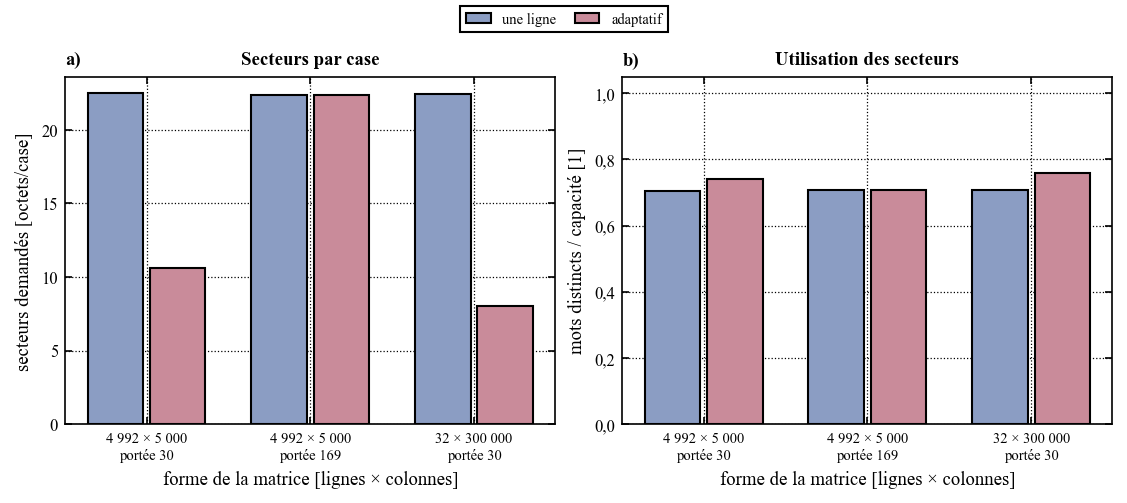

In [11]:
# Secteurs d'adresse demandés par instruction de warp, modèle de 32 octets.
loc_raw = nv_csv(RES / "locality/838447/sectors.csv")
assert set(loc_raw.schedule) == {"adaptive","single_row"}
assert set(loc_raw.access) == {"mit","diagonal","upper","gather","store"}
assert loc_raw.groupby("case").distance.nunique().eq(1).all()
loc_tot = loc_raw.groupby(["case","schedule"])[["sectors32","distinct_words"]].sum()
loc_dims = loc_raw.groupby("case")[["rows","columns","reach"]].first()
loc_cells = loc_dims.rows * loc_dims["columns"]
loc_bytes = (32 * loc_tot.sectors32 / loc_cells).unstack()
loc_fill = (loc_tot.distinct_words / (8 * loc_tot.sectors32)).unstack()
assert loc_fill.ge(0).all().all() and loc_fill.le(1).all().all()
loc_cases = list(loc_dims.sort_values(["columns","reach"]).index)
loc_labels = [f"{int(loc_dims.loc[c,'rows']):,} × {int(loc_dims.loc[c,'columns']):,}".replace(",", " ") +
              f"\nportée {int(loc_dims.loc[c,'reach'])}" for c in loc_cases]
loc_fig, loc_ax = plt.subplots(1, 2, figsize=(7.4, 3.25))
loc_x = np.arange(len(loc_cases))
for loc_ix,(loc_variant,loc_name) in enumerate([("single_row","une ligne"),("adaptive","adaptatif")]):
    loc_xi = loc_x + (loc_ix-.5)*.38
    for loc_axis,loc_data in [(loc_ax[0],loc_bytes),(loc_ax[1],loc_fill)]:
        loc_axis.bar(loc_xi,loc_data.loc[loc_cases,loc_variant],width=.34,color=COLORS[loc_ix],
                     edgecolor=INK,label=loc_name)
loc_ax[0].set_ylabel("secteurs demandés [octets/case]")
loc_ax[1].set(ylabel="mots distincts / capacité [1]", ylim=(0,1.05))
for loc_axis in loc_ax:
    loc_axis.set_xticks(loc_x,loc_labels,fontsize=7)
    loc_axis.set_xlabel("forme de la matrice [lignes × colonnes]")
label_panels(loc_ax)
column_titles(loc_ax, ('Secteurs par case', 'Utilisation des secteurs'))
legend_above(loc_fig, loc_ax, ncol=2)
nv_save(loc_fig, "14_localite_gpu")

*Figure 10.* Le panneau a) rapporte la somme des octets des secteurs de 32 octets demandés au nombre de cases. Le panneau b) mesure la part de ces octets qui correspond à des mots distincts dans l’instruction de warp. Les sommes couvrent tout le traitement des lignes.

<sub>Code : [bench/gpu_sectors.cu](../bench/gpu_sectors.cu), [bench/gpu_sectors.sbatch](../bench/gpu_sectors.sbatch), [results/locality/838447/sectors.csv](../results/locality/838447/sectors.csv), [results/locality/838447/requested-metrics.txt](../results/locality/838447/requested-metrics.txt).</sub>

Pour la forme de 4992 × 5000 cases, le calcul adaptatif demande 10,62 octets de secteurs par case, contre 22,48 pour une ligne à la fois. Pour la forme de 32 × 300000 cases, le calcul adaptatif demande 8,03 octets de secteurs par case, contre 22,42 pour une ligne à la fois. Sur le contrôle de grande portée, la récurrence utilise le noyau par ligne. Les deux décomptes de secteurs coïncident. Dans la forme large, les mots distincts remplissent 75,8 % des octets demandés par la politique adaptative. Les compteurs L1 et L2 demandés à Nsight Compute ont renvoyé ERR_NVGPUCTRPERM.

Les allocations entre deux alignements représentent un coût distinct de celui des accès du noyau.

<p><strong><u>Synthèse.</u></strong> Sur la forme large, les tuiles divisent par 2,79 les octets de secteurs demandés par case.<br>Ce rapport décrit les adresses du noyau. Le trafic HBM dépend aussi de l’état des caches.</p>

<a id="front-gpu"></a>

## Calcul par fronts de coût sur accélérateur

<hr>

La figure 11 compare les durées de trois programmes avec reconstruction du chemin et vérifie le domaine de distance du front GPU.

Pour un chemin d’édition unitaire de coût $s$, toute position $(i,j)$ vérifie $|i-j|\leq s$. Le front $s$ garde la position la plus avancée sur chaque diagonale accessible, puis prolonge les correspondances gratuites. L’implémentation IEEE 2022 testée représente uniquement $d<64$. Elle traite plusieurs paires en lot. [Aguado-Puig et coll., 2022](https://doi.org/10.1109/ACCESS.2022.3182714)

Les trois lots admissibles contiennent cinq préfixes à 2 %, quatre préfixes à 5 % et cinq paires complètes de 5 000 bases à faible distance. Un appel indépendant par configuration donne le score et un chemin. Edlib établit le coût de référence avant la sélection, puis le pilote rejoue le chemin. Les cinq répétitions chronométrent chacune un processus neuf. Le temps du lot annoncé par eWFA-GPU débute après lecture et initialisation de CUDA.

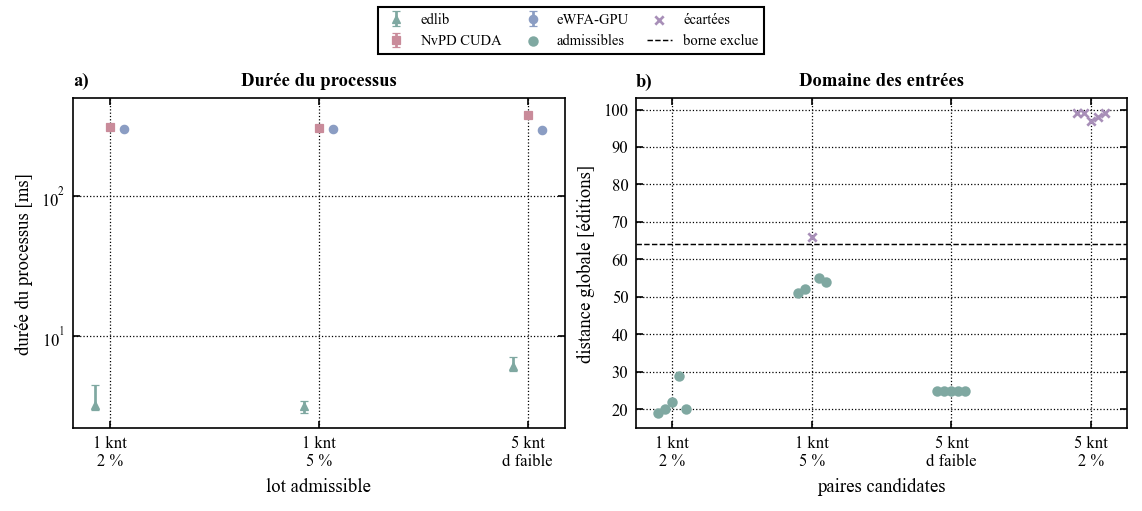

In [12]:
# Temps des processus avec chemin d'alignement et borne de la version IEEE 2022.
ew_dir = RES / "ewfa/838492"
ew_cases = ["1k_prefix_2pct","1k_prefix_5pct","5k_full_low"]
ew_raw = nv_csv(ew_dir / "trials.csv")
ew_pairs = nv_csv(ew_dir / "pairs.csv")
ew_ok = ew_pairs[ew_pairs.status.eq("verified")]
assert ew_ok.edlib.eq(pd.to_numeric(ew_ok.gpu_score)).all()
assert ew_ok.edlib.eq(pd.to_numeric(ew_ok.raw_cigar_cost)).all()
assert ew_ok.edlib.lt(64).all() and len(ew_ok)==14
assert ew_pairs[ew_pairs.status.eq("outside_d_lt_64")].edlib.ge(64).all()
assert ew_raw.groupby(["case","algorithm"]).trial.nunique().eq(5).all()
ew_fig, ew_ax = plt.subplots(1,2,figsize=(7.5,3.3))
ew_x=np.arange(len(ew_cases))
for ew_i,(ew_alg,ew_name,ew_color,ew_mark) in enumerate([("edlib","edlib",COLORS[2],"^"),
           ("nvpd-cuda","NvPD CUDA",COLORS[1],"s"),("ewfa-gpu-2022","eWFA-GPU",COLORS[0],"o")]):
    ew_t=ew_raw[ew_raw.algorithm.eq(ew_alg)].groupby("case").process_seconds.agg(["median","min","max"]).reindex(ew_cases)*1000
    ew_ax[0].errorbar(ew_x+.07*(ew_i-1),ew_t["median"],yerr=[ew_t["median"]-ew_t["min"],ew_t["max"]-ew_t["median"]],
                       fmt=ew_mark,color=ew_color,capsize=2,label=ew_name)
ew_ax[0].set(yscale="log", ylabel="durée du processus [ms]", xlabel="lot admissible")
ew_ax[0].set_xticks(ew_x,["1 knt\n2 %","1 knt\n5 %","5 knt\nd faible"])
ew_all_cases = [*ew_cases,"5k_full_2pct"]
for ew_i,ew_case in enumerate(ew_all_cases):
    ew_rows=ew_pairs[ew_pairs.case.eq(ew_case)]
    for ew_j,ew_row in enumerate(ew_rows.itertuples()):
        ew_valid=ew_row.status=="verified"
        ew_ax[1].scatter(ew_i+.05*(ew_j-(len(ew_rows)-1)/2),ew_row.edlib,
                         marker="o" if ew_valid else "x",color=COLORS[2] if ew_valid else COLORS[5],
                         label="admissibles" if ew_valid else "écartées",zorder=3)
ew_ax[1].axhline(64,**GUIDE,label="borne exclue")
ew_ax[1].set(ylabel="distance globale [éditions]", xlabel="paires candidates")
ew_ax[1].set_xticks(np.arange(4),["1 knt\n2 %","1 knt\n5 %","5 knt\nd faible","5 knt\n2 %"])
label_panels(ew_ax)
column_titles(ew_ax, ('Durée du processus', 'Domaine des entrées'))
legend_above(ew_fig, ew_ax, ncol=3)
nv_save(ew_fig, "20_front_gpu")

*Figure 11.* Le panneau a) compare les temps muraux médians avec les extrêmes de cinq processus par configuration. Le panneau b) montre le score de référence de chaque paire candidate et la limite de représentation de la version testée. Les symboles écartés sortent de son domaine.

<sub>Code : [bench/ewfa_measure.py](../bench/ewfa_measure.py), [bench/ewfa_batch.cpp](../bench/ewfa_batch.cpp), [bench/ewfa_validation.patch](../bench/ewfa_validation.patch), [results/ewfa/838492/trials.csv](../results/ewfa/838492/trials.csv), [results/ewfa/838492/pairs.csv](../results/ewfa/838492/pairs.csv).</sub>

Les cinq paires complètes à 2 % atteignent 97 à 99 éditions et un préfixe dépasse la borne avec 66 éditions. Les quatorze autres chemins binaires se rejouent et retrouvent le coût exact. Le formateur texte d’amont produit en revanche un CIGAR invalide dans ces quatorze cas. Sur les cinq paires complètes de faible distance, le lot interne eWFA-GPU dure 2,93 ms et le processus 297,3 ms. Le même lot demande 6,03 ms à edlib et 376,7 ms au processus NvPD CUDA avec reconstruction.

Les lots permettent aussi de distinguer le lancement du processus et le coût des allocations successives.

<p><strong><u>Synthèse.</u></strong> eWFA-GPU retrouve les coûts et les 14 chemins binaires dans le domaine de cette version, d &lt; 64.<br>Sur ces petits lots, le démarrage du processus GPU occupe une grande partie du temps mural.</p>

<a id="allocations-cuda"></a>

## Réutilisation des tampons entre alignements

<hr>

La figure 12 montre dans quelles collections la réutilisation des tableaux GPU réduit le coût des allocations.

Pour le lot $b$ et la répétition $r$, le gain apparié vaut $S_{b,r}=T_{b,r}^{\rm normal}/T_{b,r}^{\rm réemploi}$. Le point représente la médiane des trois rapports. Chaque exécution comprend la première allocation et la libération finale.

Le premier mode réserve et libère les deux tableaux CUDA pour chaque paire. Le second les conserve lorsque leurs tailles restent identiques. Trois lots synthétiques contiennent des séquences de même longueur. Le quatrième contient 64 génomes de φX174 de longueurs variables. L’oracle edlib et l’appel de chauffe précèdent chaque lot. Chaque mode tourne dans un processus neuf et l’ordre alterne entre les répétitions.

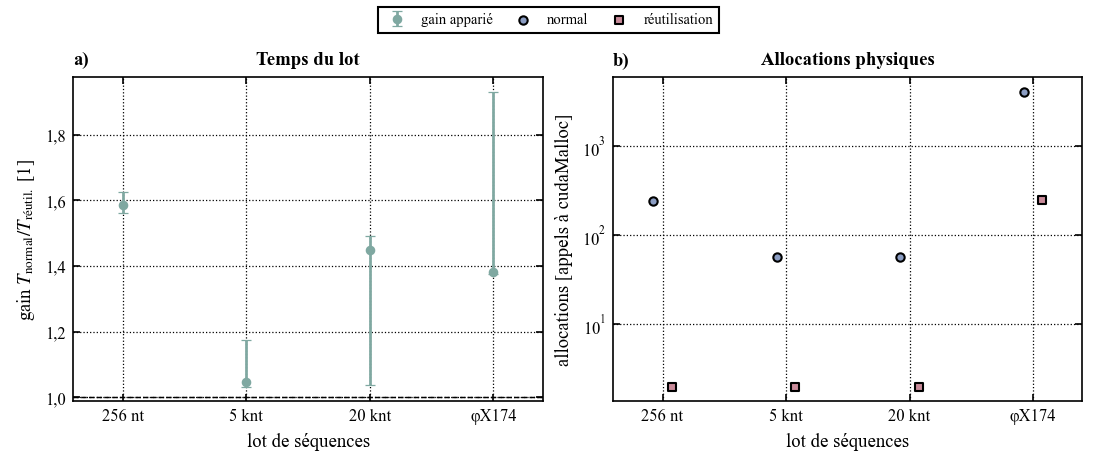

In [13]:
# Comparaison appariée sur des lots contrôlés, hors capture Nsight.
pool_alloc = nv_csv(RES / "allocator/trials.csv")
assert set(pool_alloc["mode"]) == {"normal", "reuse"}
assert set(pool_alloc["case"]) == {"fixed-256", "fixed-5000", "fixed-20000", "phix174"}
assert pool_alloc.groupby(["case", "trial"]).size().eq(2).all()
assert pool_alloc.groupby(["case", "mode"]).trial.nunique().eq(3).all()
for pool_column in ["distance_fnv64", "input_sha256", "pairs", "peak_live_bytes"]:
    assert pool_alloc.groupby("case")[pool_column].nunique().eq(1).all()
assert pool_alloc.malloc_calls.eq(pool_alloc.free_calls).all()
assert pool_alloc.groupby("case").peak_reserved_bytes.nunique().eq(1).all()
assert pool_alloc.malloc_calls.add(pool_alloc.reuse_hits).eq(2 * pool_alloc.pairs).all()
pool_ab = pool_alloc.pivot(index=["case", "trial"], columns="mode", values="seconds")
pool_alloc_stats = pool_alloc.groupby(["case", "mode"])[["seconds", "malloc_calls", "peak_reserved_bytes"]].median()
pool_cases = ["fixed-256", "fixed-5000", "fixed-20000", "phix174"]
pool_x = np.arange(len(pool_cases))
pool_labels = ["256 nt", "5 knt", "20 knt", "φX174"]
pool_fig, pool_ax = plt.subplots(1, 2, figsize=(7.2, 3.0))
pool_r = (pool_ab.normal / pool_ab.reuse).groupby("case").agg(["median", "min", "max"]).reindex(pool_cases)
pool_ax[0].errorbar(pool_x, pool_r["median"], yerr=[pool_r["median"]-pool_r["min"], pool_r["max"]-pool_r["median"]],
                    fmt="o", color=COLORS[2], capsize=2.5, label="gain apparié")
pool_ax[0].axhline(1, **GUIDE)
pool_ax[0].set(ylabel=r"gain $T_{\mathrm{normal}}/T_{\mathrm{réutil.}}$ [1]", xlabel="lot de séquences")
for pool_i, (pool_mode, pool_label) in enumerate([("normal", "normal"), ("reuse", "réutilisation")]):
    pool_c = pool_alloc_stats.xs(pool_mode, level="mode").reindex(pool_cases)
    pool_ax[1].scatter(pool_x + (pool_i-.5)*.15, pool_c.malloc_calls, marker="os"[pool_i], color=COLORS[pool_i],
                       edgecolor=INK, label=pool_label, zorder=3)
pool_ax[1].set(yscale="log", ylabel="allocations [appels à cudaMalloc]", xlabel="lot de séquences")
for pool_axis in pool_ax:
    pool_axis.set_xticks(pool_x, pool_labels)
    pool_axis.set_xlim(-.40, 3.40)
label_panels(pool_ax)
column_titles(pool_ax, ('Temps du lot', 'Allocations physiques'))
legend_above(pool_fig, pool_ax, ncol=3)
nv_save(pool_fig, "08_allocations_cuda")

*Figure 12.* Le panneau a) donne la médiane et les extrêmes des trois gains appariés entre lots. Le panneau b) compte les appels physiques à `cudaMalloc` jusqu’à la dernière libération. Chaque essai compare deux modes sur le même lot.

<sub>Code : [bench/allocator_probe.cu](../bench/allocator_probe.cu), [bench/allocator_measure.py](../bench/allocator_measure.py), [results/allocator/trials.csv](../results/allocator/trials.csv), [results/allocator/production.csv](../results/allocator/production.csv).</sub>

Les 120 alignements de séquences de 256 bases demandent 240 appels physiques à `cudaMalloc` en mode normal et deux avec réutilisation. Le gain apparié médian atteint 1,59. Sur 28 alignements de 5 000 bases, la même réduction de 56 à deux appels ne donne que 1,05 de gain, contre 1,45 sur le lot de 20 000 bases. Sur ces trois lots, le pic des tableaux reste identique dans les deux modes. Il va de 6 168 à 480 024 octets selon la longueur.

Dans un essai distinct, trois paires de processus neufs exécutent la commande complète sur φX174. Le temps médian passe de 23,60 à 9,40 s, avec un gain apparié médian de 2,48. Les six matrices sont identiques à celle d’edlib. Sur les phages, les allocations physiques passent de 4 032 à 250. Le pic explicite reste de 150 892 octets. Les temps médians de la sonde passent de 11,80 à 8,55 s. Le chronométrage de la commande complète comprend aussi le démarrage et les entrées-sorties.

Un autre portage permet d’évaluer le coût de la même récurrence dans un espace d’exécution générique.

<p><strong><u>Synthèse.</u></strong> Sur la matrice des phages, le temps du lot instrumenté diminue d’un facteur apparié de 1,38.<br>La réutilisation conserve le même pic explicite de mémoire pour chacun des quatre lots.</p>

<a id="kokkos"></a>

## Portabilité de la récurrence avec Kokkos

<hr>

La figure 13 évalue deux implémentations de NvPD utilisant la même cible matérielle.

À matériel et séquences fixés, le rapport $T_{\rm Kokkos}/T_{\rm natif}$ inclut les choix de noyau et le mode de lancement. Chaque processus réalise un appel de chauffe avant l’appel chronométré. [Edwards, Trott et Sunderland, 2014](https://doi.org/10.1016/j.jpdc.2014.07.003)

Un espace d’exécution Kokkos choisit où se déroule une boucle. Le même programme source peut soumettre une ligne de NvPD à OpenMP sur CPU ou à CUDA sur GPU. Dans ce portage, une `RangePolicy` distribue les colonnes de chaque ligne et une barrière `fence` précède la récupération du score. Sur GPU, le noyau Kokkos suit la récurrence ligne par ligne, tandis que la version CUDA native peut regrouper huit lignes en tuiles. Un processus neuf effectue un appel de chauffe puis un appel chronométré, allocations et transferts compris. Les deux implémentations alternent leur ordre entre les trois répétitions sur les mêmes entrées. Le GPU utilise CUDA 12.6.3 et l’espace d’exécution `Kokkos::Cuda`. [Boucles parallèles Kokkos](https://kokkos.org/kokkos-core-wiki/API/core/parallel-dispatch/parallel_for.html) · [Synchronisation Kokkos](https://kokkos.org/kokkos-core-wiki/API/core/parallel-dispatch/fence.html)

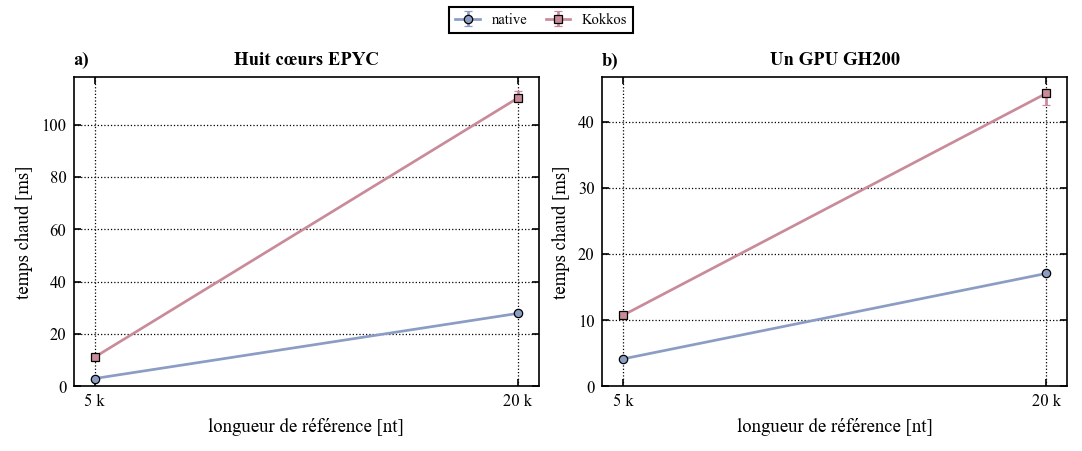

In [14]:
# Coût du portage Kokkos par rapport à l'implémentation native de chaque cible.
ko_raw = nv_csv(RES / "kokkos/timings.csv")
assert ko_raw.distance.eq(ko_raw.reference_distance).all()
ko_fig, ko_ax = plt.subplots(1, 2, figsize=(7.1, 2.9))
for ko_i, (ko_target, ko_native) in enumerate([("cpu", "nvpd-omp"), ("gpu", "nvpd-cuda")]):
    ko_sub = ko_raw[ko_raw.target.eq(ko_target)]
    ko_sub = ko_sub[ko_sub.threads.eq(ko_sub.threads.max())]
    assert set(ko_sub.algorithm) == {ko_native, "nvpd-kokkos"}
    assert set(ko_sub.m) == {5000, 20000}
    assert ko_sub.groupby("m").input_sha256.nunique().eq(1).all()
    assert ko_sub.groupby(["input_sha256", "algorithm"]).trial.nunique().eq(3).all()
    for ko_j, (ko_alg, ko_label) in enumerate([(ko_native, "native"), ("nvpd-kokkos", "Kokkos")]):
        ko_t = ko_sub[ko_sub.algorithm.eq(ko_alg)].set_index("m").seconds * 1000
        nv_band(ko_ax[ko_i], ko_t, COLORS[ko_j], ko_label, marker="os"[ko_j])
    ko_ax[ko_i].set(ylabel="temps chaud [ms]", xlabel="longueur de référence [nt]", ylim=(0, None))
    ko_len = sorted(ko_sub.m.unique())
    ko_ax[ko_i].set_xticks(ko_len, [f"{v/1000:g} k" for v in ko_len])
label_panels(ko_ax)
column_titles(ko_ax, ('Huit cœurs EPYC', 'Un GPU GH200'))
legend_above(ko_fig, ko_ax, ncol=2)
nv_save(ko_fig, "09_portage_kokkos")

*Figure 13.* Les points comparent les temps chauds des mêmes entrées avec la version native et avec Kokkos. Le panneau a) utilise huit cœurs EPYC et le panneau b) un GH200 avec quatre fils hôtes. Les barres couvrent les trois processus.

<sub>Code : [bench/kokkos_measure.py](../bench/kokkos_measure.py), [results/kokkos/timings.csv](../results/kokkos/timings.csv), [results/kokkos/checks.csv](../results/kokkos/checks.csv).</sub>

À 20 000 bases sur huit cœurs EPYC, les médianes valent 27,90 ms avec la boucle OpenMP native et 110,22 ms avec Kokkos OpenMP. Sur GH200, CUDA natif demande 17,06 ms et Kokkos CUDA 44,27 ms. À 5 000 bases, les deux temps GPU sont de 4,15 et 10,75 ms. À 20 000 bases, les deux versions GPU réservent 480 024 octets pour les mêmes tableaux de scores et d’index.

La distribution sur plusieurs nœuds ajoute la communication entre rangs.

<p><strong><u>Synthèse.</u></strong> À 20 000 bases, le rapport des durées Kokkos/native atteint 3,95 sur huit cœurs EPYC et 2,59 sur GH200.<br>Ces rapports incluent la boucle de calcul et le mécanisme de lancement de chaque version.</p>

<a id="mpi-fort"></a>

## Passage à l’échelle fort entre nœuds

<hr>

La figure 14 compare les communications d’une paire distribuée à celles d’une collection de paires indépendantes.

Pour aligner une seule paire, chaque rang MPI conserve une bande de colonnes. À chaque ligne, il partage deux scores entiers avec tous les rangs pour résoudre les dépendances qui traversent une frontière. L’expérience affecte 24 rangs de huit fils OpenMP à chaque nœud. Pour une collection, le programme distribue des paires indépendantes entre les rangs puis entre les fils OpenMP. Une seule réduction finale réunit les distances. Un nœud compte 192 cœurs actifs et deux nœuds en comptent 384 avec la même disposition des équipes. [Implémentation distribuée](../src/mpi.cpp) · [Norme MPI, opérations collectives](https://www.mpi-forum.org/docs/mpi-4.1/mpi41-report/mpi41-report.htm)

Les mesures à un et deux nœuds utilisent les mêmes séquences dans une réservation exclusive. Chaque essai commence après une barrière, puis le pilote conserve la durée du rang le plus lent. Le rapport $S=T_1/T_2$ donne le gain du second nœud. L’efficacité de ce doublement est $S/2$. Les trois répétitions suivent un appel de chauffe.

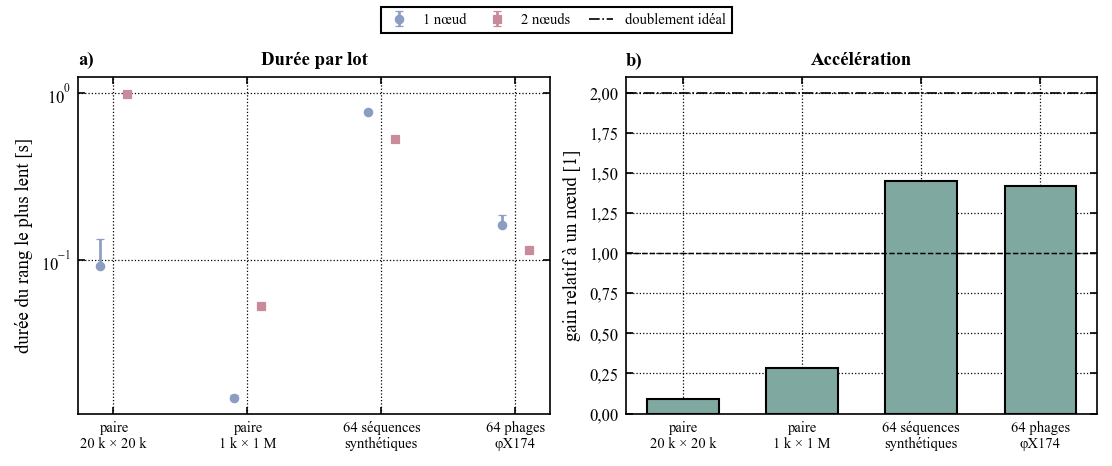

In [15]:
# Mesure du passage de un à deux nœuds complets (results/mpi/838226/trials.csv).
mp_raw = nv_csv(RES / "mpi/838226/trials.csv")
assert mp_raw.groupby("case").input_sha256.nunique().eq(1).all()
assert mp_raw.groupby("case").distance_or_matrix_sha256.nunique().eq(1).all()
assert mp_raw.groupby(["case","nodes"]).trial.nunique().eq(3).all()
assert mp_raw.assigned_workers.eq(mp_raw.step_cores).all()
assert mp_raw.sampled_physical_cores.eq(mp_raw.nodes * 192).all()
assert set(mp_raw.oracle_algorithm) == {"edlib"}
mp_cases = {"square":"paire\n20 k × 20 k", "wide":"paire\n1 k × 1 M",
            "synthetic64":"64 séquences\nsynthétiques", "phix64":"64 phages\nφX174"}
mp_times = mp_raw.groupby(["case","nodes"]).seconds.agg(["median","min","max"])
mp_x = np.arange(len(mp_cases))
# Contrôle du second essai sur un seul nœud, chronométré du lancement à la sortie.
mp_cli = nv_csv(RES / "profile/matrix-omp/838652/trials.csv")
assert mp_cli.threads.eq(8).all() and mp_cli.pairs.eq(120).all()
assert mp_cli.input_sha256.nunique() == mp_cli.matrix_sha256.nunique() == 1
mp_cli_wall = mp_cli.pivot(index="trial", columns="layout", values="wall_seconds")
assert mp_cli_wall.shape == (5, 2) and mp_cli_wall.notna().all().all()
mp_cli_gain = (mp_cli_wall["intra"] / mp_cli_wall["inter"]).median()
mp_fig, mp_ax = plt.subplots(1, 2, figsize=(7.3, 3.0))
for mp_i, mp_nodes in enumerate([1, 2]):
    mp_g = mp_times.xs(mp_nodes,level="nodes").reindex(mp_cases)
    mp_ax[0].errorbar(mp_x + .10*(2*mp_i-1), mp_g["median"], fmt="os"[mp_i],
                      yerr=[mp_g["median"]-mp_g["min"], mp_g["max"]-mp_g["median"]],
                      color=COLORS[mp_i], capsize=2, label=f"{mp_nodes} nœud" + ("s" if mp_nodes==2 else ""))
mp_one = mp_times.xs(1,level="nodes").reindex(mp_cases)["median"]
mp_two = mp_times.xs(2,level="nodes").reindex(mp_cases)["median"]
mp_ax[1].bar(mp_x, mp_one/mp_two, width=.6, color=COLORS[2], edgecolor=INK)
mp_ax[1].axhline(1, **GUIDE)
mp_ax[1].axhline(2, color=INK, lw=.8, ls="-.", label="doublement idéal")
for mp_axis in mp_ax:
    mp_axis.set_xticks(mp_x, mp_cases.values(), fontsize=7)
mp_ax[0].set(yscale="log", ylabel="durée du rang le plus lent [s]")
mp_ax[1].set(ylabel="gain relatif à un nœud [1]", ylim=(0, None))
label_panels(mp_ax)
column_titles(mp_ax, ('Durée par lot', 'Accélération'))
legend_above(mp_fig, mp_ax, ncol=3)
nv_save(mp_fig, "10_echelle_mpi")

*Figure 14.* Les durées représentent le temps du rang le plus lent pour trois essais de chaque configuration. Le panneau b) rapporte les médianes à celle de deux nœuds. La ligne horizontale à un indique l’égalité des durées.

<sub>Code : [src/mpi.cpp](../src/mpi.cpp), [bench/mpi.sbatch](../bench/mpi.sbatch), [bench/mpi_benchmark.py](../bench/mpi_benchmark.py), [results/mpi/838226/trials.csv](../results/mpi/838226/trials.csv), [bench/matrix_omp.py](../bench/matrix_omp.py), [results/profile/matrix-omp/838652/trials.csv](../results/profile/matrix-omp/838652/trials.csv).</sub>

Sur la paire presque carrée, passer de 192 à 384 cœurs porte le temps de 91 à 990 ms. Chaque alignement échange les frontières 20 000 fois. La paire large effectue 1 024 échanges et passe de 14,8 à 52,6 ms. La forte hausse temporelle coïncide avec la communication inter-nœuds, mais le chronométrage global ne sépare pas le temps des collectives de celui du calcul.

Sur les 2 016 paires synthétiques, le temps médian passe de 0,764 à 0,528 s (1,45×). Sur les 64 phages, il passe de 0,162 à 0,115 s (1,42×). Pour les quatre cas, la distance scalaire ou l’empreinte de la matrice coïncide avec celle d’edlib et les contrôles d’affinité trouvent bien 192 puis 384 cœurs physiques.

Sur un seul nœud EPYC, un second essai utilise les mêmes huit cœurs pour construire une matrice de 120 paires synthétiques. Si les huit fils se partagent les colonnes de chaque paire, le processus dure 227,3 ms en médiane. Si chaque fil traite une paire entière, cette durée tombe à 43,5 ms. Le gain médian des cinq essais appariés vaut 5,26 et les dix matrices reproduisent la référence edlib.

Le passage à l’échelle faible conserve la charge par nœud pour examiner séparément son effet.

<p><strong><u>Synthèse.</u></strong> Les matrices synthétique et de phages atteignent respectivement 72 % et 71 % d’efficacité sur deux nœuds.<br>Sur une paire isolée, l’échange entre rangs à chaque ligne allonge le calcul.</p>

<a id="mpi-faible"></a>

## Passage à l’échelle faible entre nœuds

<hr>

La figure 15 suit la durée et le débit lorsque le nombre de nœuds et le travail total augmentent ensemble.

Pour $p$ nœuds et un travail $W$ par nœud, l’efficacité faible vaut $E_w(p)=T_1(W)/T_p(pW)$. Si le travail total double entre un et deux nœuds, le rapport des débits vaut $2E_w(2)$.

Les paires isolées ont 1 024 lignes et gardent 256 ou 4 096 colonnes par cœur. Le lot de 85 séquences sur un nœud produit 3 570 paires. Celui de 120 séquences en produit 7 140 sur deux nœuds. Chaque séquence synthétique du lot mesure 8 192 bases. La charge dense par cœur reste constante dans chaque cas. Le pilote vérifie les distances ou les matrices avec edlib et mesure le rang le plus lent après chauffe.

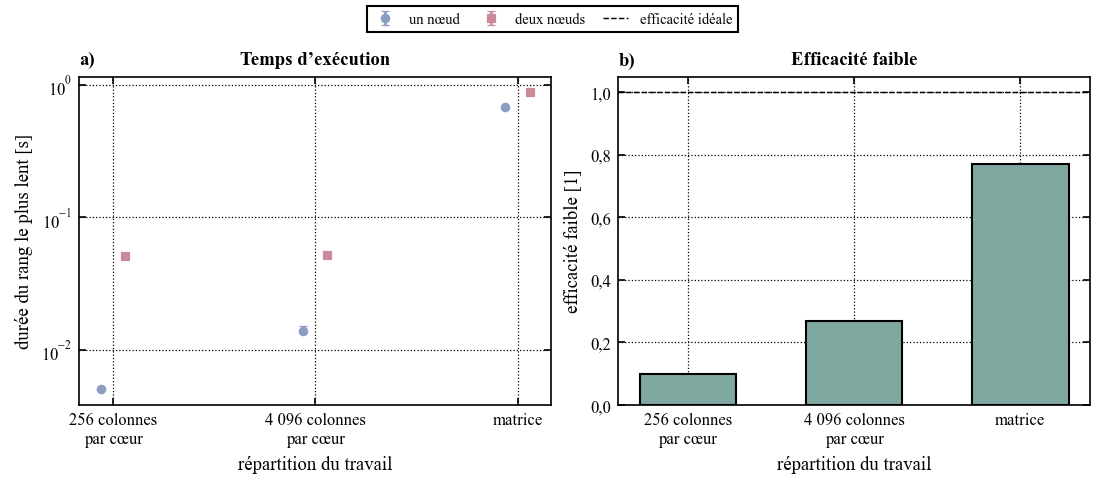

In [16]:
# Comparaison à charge constante par cœur sur un et deux nœuds.
wk_raw = nv_csv(RES / "mpi/weak/838444/trials.csv")
wk_summary = nv_csv(RES / "mpi/weak/838444/summary.csv").set_index("case")
wk_cases = ["pair_256", "pair_4096", "matrix"]
assert set(wk_summary.index) == set(wk_cases)
assert wk_raw.groupby("case").cells_per_core.nunique().eq(1).all()
assert wk_raw.sampled_physical_cores.eq(192 * wk_raw.nodes).all()
assert wk_raw.groupby(["case","nodes"]).trial.nunique().eq(5).all()
wk_times = wk_raw.groupby(["case","nodes"]).seconds.agg(["median","min","max"])
wk_ratio = wk_times.xs(1,level="nodes")["median"] / wk_times.xs(2,level="nodes")["median"]
assert np.allclose(wk_ratio, wk_summary.loc[wk_ratio.index, "weak_efficiency"])
wk_fig, wk_ax = plt.subplots(1, 2, figsize=(7.25, 3.15))
wk_x = np.arange(len(wk_cases))
for wk_index, wk_nodes in enumerate([1, 2]):
    wk_t = wk_times.xs(wk_nodes, level="nodes").reindex(wk_cases)
    wk_ax[0].errorbar(wk_x + (wk_index-.5)*.12, wk_t["median"],
                      yerr=[wk_t["median"]-wk_t["min"], wk_t["max"]-wk_t["median"]],
                      fmt="os"[wk_index],color=COLORS[wk_index],capsize=2,label=["un nœud","deux nœuds"][wk_index])
wk_ax[0].set(yscale="log", ylabel="durée du rang le plus lent [s]")
wk_ax[1].bar(wk_x, wk_ratio.reindex(wk_cases), width=.58, color=COLORS[2], edgecolor=INK)
wk_ax[1].axhline(1, **GUIDE, label="efficacité idéale")
wk_ax[1].set(ylabel="efficacité faible [1]", ylim=(0, None))
for wk_axis in wk_ax:
    wk_axis.set_xticks(wk_x, ["256 colonnes\npar cœur","4 096 colonnes\npar cœur","matrice"])
    wk_axis.set_xlabel("répartition du travail")
label_panels(wk_ax)
column_titles(wk_ax, ('Temps d’exécution', 'Efficacité faible'))
legend_above(wk_fig, wk_ax, ncol=3)
nv_save(wk_fig, "15_mpi_faible")

*Figure 15.* Les temps proviennent de cinq essais avec 192 ou 384 cœurs physiques. L’efficacité en b) rapporte le temps à un nœud au temps à deux nœuds pour une charge constante par cœur. La droite horizontale marque l’efficacité idéale.

<sub>Code : [bench/mpi_weak.py](../bench/mpi_weak.py), [results/mpi/weak/838444/trials.csv](../results/mpi/weak/838444/trials.csv), [results/mpi/weak/838444/summary.csv](../results/mpi/weak/838444/summary.csv).</sub>

Pour une paire distribuée, l’efficacité faible vaut 9,9 % avec 256 colonnes par cœur, puis 26,8 % avec 4 096 colonnes. Pour la matrice, le temps médian passe de 0,687 à 0,893 s. Son débit est multiplié par 1,54.

La distance entre deux assemblages humains fournit ensuite un cas où la taille de l’entrée domine.

<p><strong><u>Synthèse.</u></strong> À travail fixe par cœur, la matrice conserve 76,9 % d’efficacité au passage d’un à deux nœuds.<br>L’alignement d’une seule paire reste sensible aux échanges entre rangs à chaque ligne.</p>

<a id="chromosome"></a>

## Distances entre assemblages d’un chromosome humain

<hr>

La figure 16 compare le temps et la mémoire nécessaires à l’alignement de deux assemblages du chromosome humain.

Le contrôle par insertions donne $d\geq |n-m|=64$. La liste des 64 insertions fournit la borne opposée. Les fenêtres naturelles utilisent des paires d’intervalles orientés dans le même sens et désignés par les coordonnées du manifeste. [Nurk et coll., 2022](https://doi.org/10.1126/science.abj6987)

La chaîne de correspondance de hg38 vers hs1 permet de retrouver dans l’assemblage T2T-CHM13 les bornes de deux intervalles du chromosome 21 de GRCh38. Les positions sont indexées depuis zéro et la borne de fin est exclue. Les fenêtres GRCh38 commencent toutes les deux à 34 000 000 et se terminent à 36 000 000 et 38 000 000. La première est donc incluse dans la seconde. La chaîne sert à choisir les intervalles, puis chaque algorithme calcule une distance globale sur les chaînes FASTA complètes de la paire. [Manifeste et coordonnées](../results/human/manifest.tsv) · [Chaîne de correspondance UCSC](https://hgdownload.soe.ucsc.edu/goldenPath/hg38/liftOver/hg38ToHs1.over.chain.gz)

Le contrôle utilise le chromosome 21 entier de T2T-CHM13, long de 45 090 682 bases, face à une copie où le générateur insère 64 lettres.

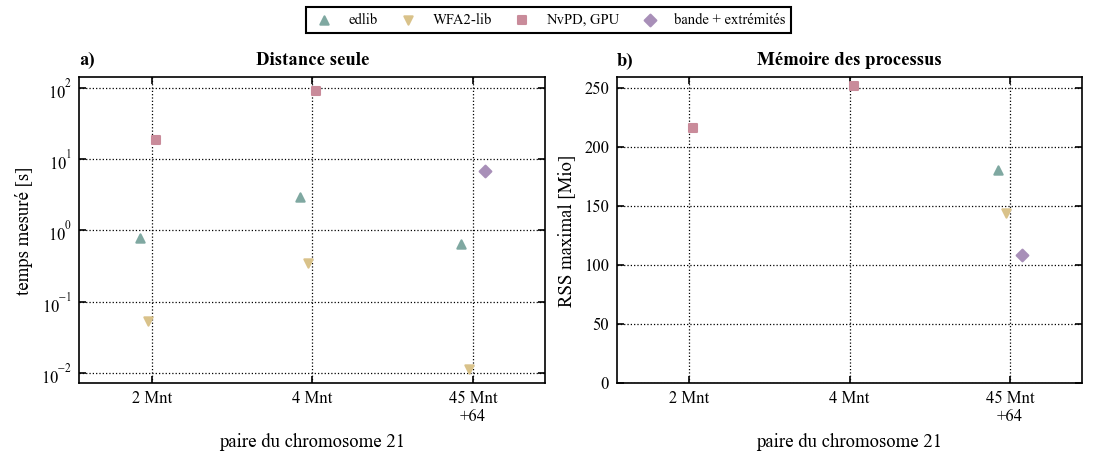

In [17]:
# Intervalles homologues et contrôle synthétique sur fond de chromosome réel.
hu_manifest = pd.read_csv(RES / "human/manifest.tsv", sep="\t").set_index("case")
hu_raw = nv_csv(RES / "human/838220/trials.csv")
hu_ok = hu_raw[hu_raw.status.eq("ok")].copy()
assert hu_ok.groupby("case").distance.nunique().eq(1).all()
assert hu_ok.groupby(["case", "algorithm"]).trial.nunique().eq(2).all()
assert hu_ok.input_sha256.eq(hu_ok.case.map(hu_manifest.sha256)).all()
assert (hu_ok.m == hu_ok.case.map(hu_manifest.m)).all() and (hu_ok.n == hu_ok.case.map(hu_manifest.n)).all()
assert hu_ok.loc[hu_ok.case.eq("chr21-full-insert64"), "distance"].eq(64).all()
hu_spot = pd.read_json(RES / "kokkos/human.json", typ="series")
assert hu_spot.distance == hu_spot.reference_distance == hu_ok.loc[hu_ok.case.eq("chr21-2m"), "distance"].iloc[0]
assert hu_spot.input_sha256 == hu_manifest.loc["chr21-2m", "sha256"]
hu_order = ["chr21-2m", "chr21-4m", "chr21-full-insert64"]
hu_fig, hu_ax = plt.subplots(1, 2, figsize=(7.2, 3.0))
# Un point par algorithme et cas mesuré. Une absence de point reste visible.
for hu_i, hu_alg in enumerate(hu_ok.algorithm.unique()):
    hu_g = hu_ok[hu_ok.algorithm.eq(hu_alg)].groupby("case")
    hu_t = hu_g.seconds.median().reindex(hu_order)
    hu_rss = hu_g.peak_rss_kib.max().reindex(hu_order).replace(0, np.nan) / 1024
    hu_label, hu_col, hu_mark = (("bande + extrémités", COLORS[5], "D") if hu_alg == "banded-trim"
                                  else nv_methods[hu_alg])
    hu_pos = np.arange(3) + .05*(hu_i - (hu_ok.algorithm.nunique()-1)/2)
    hu_ax[0].scatter(hu_pos, hu_t, color=hu_col, marker=hu_mark, label=hu_label, zorder=3)
    hu_ax[1].scatter(hu_pos, hu_rss, color=hu_col, marker=hu_mark, label=hu_label, zorder=3)
for hu_axis in hu_ax:
    hu_axis.set_xticks(range(3), ["2 Mnt", "4 Mnt", "45 Mnt\n+64"])
    hu_axis.set_xlim(-.45, 2.45)
hu_ax[0].set(yscale="log", ylabel="temps mesuré [s]", xlabel="paire du chromosome 21")
hu_ax[1].set(ylabel="RSS maximal [Mio]", xlabel="paire du chromosome 21", ylim=(0, None))
label_panels(hu_ax)
column_titles(hu_ax, ('Distance seule', 'Mémoire des processus'))
legend_above(hu_fig, hu_ax, ncol=4)
nv_save(hu_fig, "11_chromosome21")

*Figure 16.* Les deux fenêtres homologues et le chromosome modifié fournissent trois paires distinctes. Les points en a) représentent le temps médian de deux appels. Les points en b) donnent le plus haut pic RSS hôte des deux processus. Le système a renvoyé zéro pour certains RSS, laissés manquants.

<sub>Code : [scripts/human_reference.py](../scripts/human_reference.py), [results/human/838220/trials.csv](../results/human/838220/trials.csv), [results/kokkos/human.json](../results/kokkos/human.json).</sub>

Les deux fenêtres donnent 5 599 et 12 482 éditions. À 4 Mnt, les deux exécutions de NvPD sur GPU demandent 90,60 et 91,18 s. Les médianes de WFA2-lib et d’edlib valent 0,35 et 2,99 s sur le CPU Grace. Les portées gauches maximales de 290 et 622 colonnes dépassent le seuil de 64. Le noyau CUDA lit donc une ligne à la fois, y compris avec la version adaptative. À 4 Mnt, il réserve 91,6 Mio en mémoire globale, pour un pic de RSS hôte de 252 Mio. Sur le contrôle entier, le calcul WFA2-lib demande 0,011 s et la commande complète 0,48 s, lecture des deux chromosomes comprise. Le processus Kokkos CUDA du job 838230 retrouve 5 599 sur la fenêtre de deux millions de bases en 24,20 s, avec 48 030 336 octets explicites. Sa chaîne de compilation et son initialisation diffèrent de celles de la comparaison native.

Lorsque les deux séquences diffèrent peu, restreindre les états explorés peut réduire le travail.

<p><strong><u>Synthèse.</u></strong> Les trois méthodes appliquées au chromosome de 45,1 millions de bases avec 64 insertions retrouvent exactement 64.<br>Sur les fenêtres naturelles, la portée du prédécesseur contraint NvPD CUDA à avancer ligne par ligne.</p>

<a id="assemblages-entiers"></a>

## Comparaison de chromosomes humains entiers

<hr>

La figure 17 compare les temps de calcul du chromosome 20 et les bornes disponibles pour la distance entre les deux références du chromosome 21.

Pour la lettre $c$, $s_a=\sum_c\max(h_a(c)-h_b(c),0)$ compte les excédents de $a$, et $s_b$ ceux de $b$. Chaque édition résout au plus un excédent de chaque côté. Ainsi $\max(s_a,s_b)\leq d(a,b)$. Une chaîne de correspondance monotone entre les assemblages fournit un alignement explicite de coût $U$, donc $d(a,b)\leq U$.

Les séquences CP068258.1 et CP068258.2 représentent les versions 1.0 et 2.0 du chromosome 20 de T2T-CHM13. Les longueurs valent 66 210 247 et 66 210 255 bases. Sur le chromosome 21, GRCh38 et CHM13 mesurent respectivement 46 709 983 et 45 090 682 bases. Le programme aligne les chaînes déposées, avec un coût unitaire et une comparaison littérale des symboles ambigus. Un processus indépendant sur un cœur EPYC dispose de 120 s par appel et 4 Gio d’espace d’adressage. Les six exécutions sur le chromosome 20 alternent les deux algorithmes. Sur le chromosome 21, chaque algorithme fait une tentative.

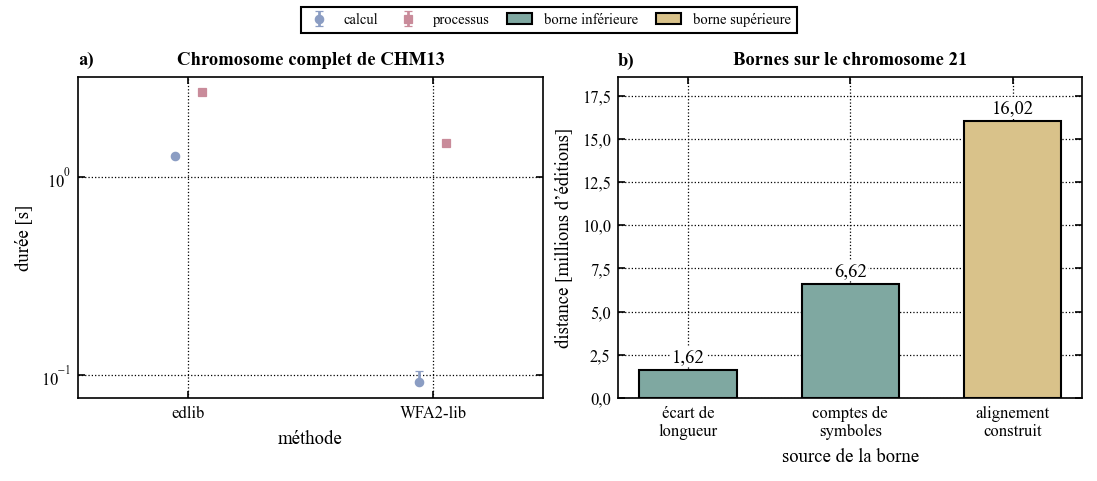

In [18]:
# Calcul terminé ou observation censurée sur les deux chromosomes entiers.
wh_raw = nv_csv(RES / "human/whole/838443/trials.csv")
wh_manifest = pd.read_csv(RES / "human/whole/manifest.tsv", sep="\t").set_index("case")
assert wh_raw.input_sha256.eq(wh_raw.case.map(wh_manifest.sha256)).all()
wh_bounds = nv_csv(RES / "human/whole/bounds.csv").iloc[0]
assert wh_bounds.lower == max(wh_bounds.surplus_a, wh_bounds.surplus_b)
assert wh_bounds.length_gap == abs(wh_bounds.m-wh_bounds.n) and wh_bounds.length_gap <= wh_bounds.lower <= wh_bounds.upper
wh_first = wh_raw[wh_raw.case.eq("chr20-assemblies")].copy()
assert wh_first.groupby("method").trial.nunique().eq(3).all()
assert wh_first.status.eq("ok").all() and pd.to_numeric(wh_first.distance).eq(30).all()
wh_first["seconds"] = pd.to_numeric(wh_first.seconds)
wh_second = wh_raw[wh_raw.case.eq("chr21-assemblies")].set_index("method")
wh_order = ["edlib","wfa2"]
wh_labels = ["edlib","WFA2-lib"]
wh_fig, wh_ax = plt.subplots(1, 2, figsize=(7.2, 3.1))
wh_x = np.arange(2)
for wh_ix,(wh_metric,wh_label) in enumerate([("seconds","calcul"),("wall_seconds","processus")]):
    wh_s = wh_first.groupby("method")[wh_metric].agg(["median","min","max"]).reindex(wh_order)
    wh_ax[0].errorbar(wh_x+(wh_ix-.5)*.11,wh_s["median"],
                      yerr=[wh_s["median"]-wh_s["min"],wh_s["max"]-wh_s["median"]],
                      fmt="os"[wh_ix],color=COLORS[wh_ix],capsize=2,label=wh_label)
wh_ax[0].set(yscale="log", ylabel="durée [s]")
wh_ax[0].set_xticks(wh_x, wh_labels)
wh_ax[0].set(xlabel="méthode", xlim=(-.45,1.45))
wh_limits = [wh_bounds.length_gap, wh_bounds.lower, wh_bounds.upper]
wh_names = ["écart de\nlongueur", "comptes de\nsymboles", "alignement\nconstruit"]
for wh_idx,wh_count in enumerate(wh_limits):
    wh_low = wh_idx < 2
    wh_height = wh_count / 1e6
    wh_ax[1].bar(wh_idx, wh_height, width=.60, color=COLORS[2 if wh_low else 3], edgecolor=INK,
                 label="borne inférieure" if wh_low else "borne supérieure")
    wh_ax[1].annotate(f"{wh_height:.2f}".replace(".",","), (wh_idx,wh_height),
                      xytext=(0,4), textcoords="offset points", ha="center",
                      bbox=dict(facecolor=PAPER,edgecolor=PAPER,pad=.3))
wh_ax[1].set_xticks(range(3), wh_names)
wh_ax[1].set(ylabel="distance [millions d’éditions]",xlabel="source de la borne",
             ylim=(0,1.16*max(wh_limits)/1e6))
assert wh_second.status.eq("wall_limit_120s").all()
label_panels(wh_ax)
column_titles(wh_ax, ('Chromosome complet de CHM13', 'Bornes sur le chromosome 21'))
legend_above(wh_fig, wh_ax, ncol=4)
nv_save(wh_fig, "18_chromosomes_entiers")

*Figure 17.* Pour le chromosome 20 de CHM13, le panneau a) présente le temps médian du calcul et du processus sur trois essais. Sur le chromosome 21 entre références, les deux méthodes atteignent la limite de 120 s. Le panneau b) place sur une même échelle les deux bornes inférieures et le coût de l’alignement construit.

<sub>Code : [bench/whole_chromosomes.py](../bench/whole_chromosomes.py), [results/human/whole/manifest.tsv](../results/human/whole/manifest.tsv), [results/human/whole/838443/trials.csv](../results/human/whole/838443/trials.csv), [bench/chromosome_bounds.py](../bench/chromosome_bounds.py), [results/human/whole/bounds.csv](../results/human/whole/bounds.csv).</sub>

Sur le chromosome 20, les six appels donnent 30 éditions. Le temps de calcul médian atteint 0,092 s avec WFA2-lib et 1,280 s avec edlib. Sur le chromosome 21, les deux processus atteignent la limite, après 120,119 s pour WFA2-lib et 120,125 s pour edlib. La chaîne et les comptes de symboles donnent $6\,621\,364\leq d\leq16\,015\,052$. Le seul écart de longueur donne la borne de 1 619 301. La campagne ne fournit aucun score exact pour cette paire.

Les méthodes sensibles au score permettent d’examiner comment la position des différences intervient.

<p><strong><u>Synthèse.</u></strong> Pour le chromosome 21 entre références, la distance reste comprise entre 6 621 364 et 16 015 052 éditions.<br>Les deux tentatives bornées ne fournissent pas de score exact pour cette paire.</p>

<a id="methodes-distance"></a>

## Méthodes exactes sensibles à la distance

<hr>

La figure 18 examine la réduction du temps de calcul lorsque les erreurs se concentrent dans une bande ou dans un intervalle court.

La bande adaptative cherche d’abord un chemin de faible coût dans un couloir autour de la diagonale. Si le seuil est insuffisant, elle élargit le couloir jusqu’à certifier la distance globale. La variante `banded-trim` supprime aussi le préfixe et le suffixe communs avant ce calcul. En distance d’édition unitaire, deux lettres terminales identiques peuvent être appariées gratuitement. Supprimer ces extrémités conserve donc le score. Pour un seuil $k$, un chemin dont le coût est inférieur ou égal à $k$ reste dans $|i-j|\leq k$. L’implémentation double $k$ après chaque essai infructueux. Le temps gagné par le retrait des extrémités dépend de leur longueur. [Ukkonen, recherche à seuil](https://doi.org/10.1016/S0019-9958%2885%2980046-2)

Les bibliothèques C et C++ utilisent GCC 16.1 sur Apple M1 Pro. Les deux modes A*PA2 utilisent la bibliothèque Rust et restituent leur CIGAR. La durée inclut sa libération. Les essais sont monothread, sans affinité CPU imposée sur le Mac. Chaque exécution lance un nouveau processus. L’ordre des sept configurations change à chaque répétition selon un générateur de graine fixée.

QuickEd utilise un schéma de borne puis d’alignement pour retrouver une distance exacte. A*PA2 associe programmation dynamique bit-parallèle, élargissement de bande et guidage heuristique. Ding et coll. proposent une autre famille d’algorithmes parallèles dont le travail dépend de la distance. La figure compare A*PA2 simple et complet aux cinq autres configurations sur les mêmes entrées. Les résultats de Ding et coll. restent bibliographiques. Sassy, de R. Beeloo et R. Groot Koerkamp, recherche les occurrences approchées d’un motif dans un texte. Le programme mm2-plus accélère le placement et l’alignement de segments par minimap2, une tâche différente du calcul d’un unique score global exact. [QuickEd, 2025](https://doi.org/10.1093/bioinformatics/btaf112) · [A*PA2, 2024](https://doi.org/10.4230/LIPIcs.WABI.2024.17) · [Ding et coll., 2023](https://doi.org/10.4230/LIPIcs.ESA.2023.40) · [Sassy, 2026](https://doi.org/10.1093/bioinformatics/btag244) · [mm2-plus, 2026](https://doi.org/10.1093/bioinformatics/btag083)

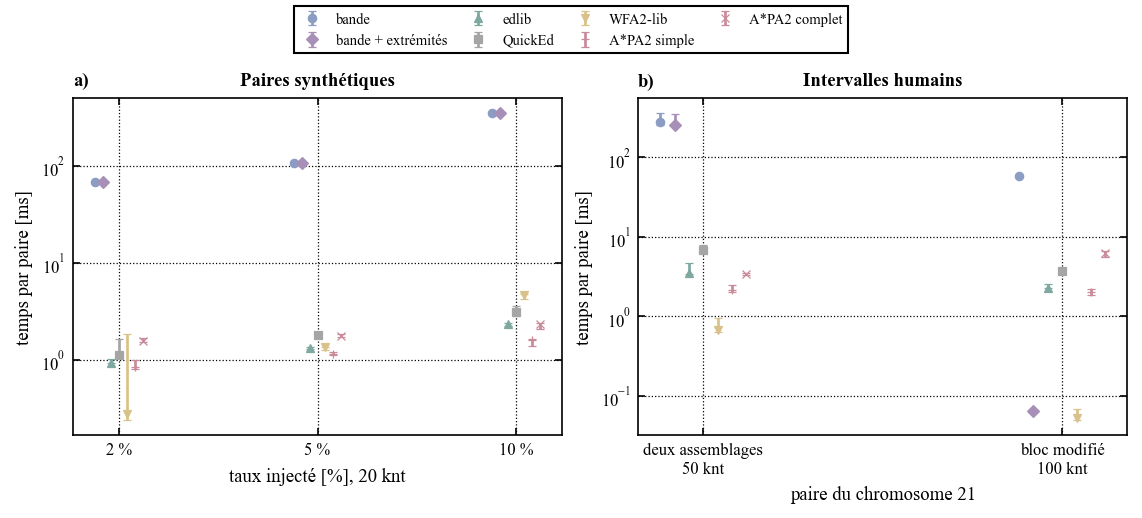

In [19]:
# Essais des méthodes exactes à entrée et machine identiques.
al_raw = nv_csv(RES / "alternatives/astar.csv")
al_ok = al_raw[al_raw.machine.eq("apple-m1-pro")]
assert al_ok.groupby(["case", "variant"]).trial.nunique().eq(5).all()
assert al_ok.groupby("case").sha256.nunique().eq(1).all()
assert al_ok.groupby("case").variant.nunique().eq(7).all()
assert al_ok.groupby(["machine", "case"]).distance.nunique().eq(1).all()
al_previous = nv_csv(RES / "alternatives/trials.csv")
al_cross = pd.concat([al_previous, al_ok])
assert al_cross.groupby("case").sha256.nunique().eq(1).all() and al_cross.groupby("case").distance.nunique().eq(1).all()
al_fig, al_ax = plt.subplots(1, 2, figsize=(7.5, 3.35))
al_method = {"banded": ("bande", COLORS[0], "o"), "banded-trim": ("bande + extrémités", COLORS[5], "D"),
             "edlib": nv_methods["edlib"], "quicked": ("QuickEd", COLORS[4], "s"), "wfa2": nv_methods["wfa2"],
             "astarpa2-simple": ("A*PA2 simple", COLORS[1], "+"), "astarpa2-full": ("A*PA2 complet", COLORS[1], "x")}
al_sets = [["20k-0.02", "20k-0.05", "20k-0.1"], ["chr21-50k", "chr21-center128"]]
for al_j, al_cases in enumerate(al_sets):
    for al_k, (al_v, (al_name, al_color, al_mark)) in enumerate(al_method.items()):
        al_t = (al_ok[al_ok.variant.eq(al_v)].groupby("case").seconds
                .agg(["median", "min", "max"]).reindex(al_cases) * 1000)
        al_x = np.arange(len(al_cases)) + (al_k-3)*.040
        al_ax[al_j].errorbar(al_x, al_t["median"], fmt=al_mark,
                             color=al_color, capsize=2, label=al_name,
                             yerr=[al_t["median"]-al_t["min"], al_t["max"]-al_t["median"]])
    al_ax[al_j].set(yscale="log", ylabel="temps par paire [ms]")
al_ax[0].set_xticks(range(3), ["2 %", "5 %", "10 %"])
al_ax[0].set_xlabel("taux injecté [%], 20 knt")
al_ax[1].set_xticks(range(2), ["deux assemblages\n50 knt", "bloc modifié\n100 knt"])
al_ax[1].set_xlabel("paire du chromosome 21")
label_panels(al_ax)
column_titles(al_ax, ('Paires synthétiques', 'Intervalles humains'))
legend_above(al_fig, al_ax, ncol=4)
nv_save(al_fig, "12_methodes_exactes")

*Figure 18.* Chaque point représente la durée médiane de cinq processus monothread sur Apple M1 Pro. Le panneau a) couvre trois taux d’erreur à 20 knt. Le panneau b) couvre une paire naturelle à 50 knt et un contrôle de 100 knt avec modifications centrales.

<sub>Code : [src/banded.cpp](../src/banded.cpp), [src/quicked_adapter.c](../src/quicked_adapter.c), [src/quicked_main.cpp](../src/quicked_main.cpp), [tests/quicked.py](../tests/quicked.py), [bench/alternatives.py](../bench/alternatives.py), [results/alternatives/trials.csv](../results/alternatives/trials.csv), [bench/astar_trial.cpp](../bench/astar_trial.cpp), [results/alternatives/astar.csv](../results/alternatives/astar.csv).</sub>

Sur les intervalles homologues de 50 000 bases, les sept configurations retrouvent 698 éditions. WFA2-lib demande 0,67 ms, A*PA2 simple 2,16 ms et A*PA2 complet 3,42 ms. Pour les paires de 20 000 bases à 10 %, A*PA2 simple prend 1,59 ms et WFA2-lib 4,67 ms. Sur le contrôle de 100 000 bases à distance 72, supprimer les extrémités identiques ramène la bande de 58,90 à 0,064 ms. Les 175 distances concordent entre les méthodes et avec les entrées correspondantes de la première série de 125 mesures.

Sur une paire distincte de répétitions décalées de 512 bases, QuickEd 1.2 a renvoyé 954 pour une distance vérifiée de 128. Le pilote compare après chronométrage le score d’amont à celui d’edlib et refuse un résultat discordant.

Chaque coût ainsi vérifié peut devenir une entrée d’une matrice de distances entre génomes.

<p><strong><u>Synthèse.</u></strong> Sur le contrôle modifié au centre, le retrait des extrémités rend le calcul en bande environ 920 fois plus rapide.<br>Sur la paire naturelle de 50 000 bases, WFA2-lib obtient le temps le plus court des sept configurations.</p>

<a id="phylogenie"></a>

## Structure des distances entre génomes de phages

<hr>

La figure 19 mesure les écarts aux hypothèses de chaque arbre reconstruit à partir des distances d’édition.

Pour trois feuilles, $g_3=d_{(3)}-d_{(2)}$ est la différence entre les deux plus grandes distances. Un arbre ultramétrique impose $g_3=0$. Pour quatre feuilles, on forme $d_{ij}+d_{kl}$ avec les trois appariements distincts. L’additivité impose l’égalité des deux plus grandes sommes, soit $g_4=0$. Le résidu entre deux feuilles est $r_{ij}=\ell_{ij}-d_{ij}$, où $\ell_{ij}$ est la somme des branches reliant les feuilles.

Chaque matrice contient les 2 016 distances des 64 génomes complets de φX174. Les programmes calculent la distance globale sur les chaînes déposées. Celle-ci dépend de l’origine choisie pour un chromosome circulaire. UPGMA joint les groupes dont la moyenne des distances est minimale et place toutes les feuilles à la même hauteur. Neighbor-Joining utilise les sommes de distances à tous les autres groupes et produit un arbre non enraciné. Les tests portent sur tous les triplets et tous les quartets. [Sokal et Michener, 1958](https://www.biodiversitylibrary.org/part/385476) · [Saitou et Nei, 1987](https://doi.org/10.1093/oxfordjournals.molbev.a040454)

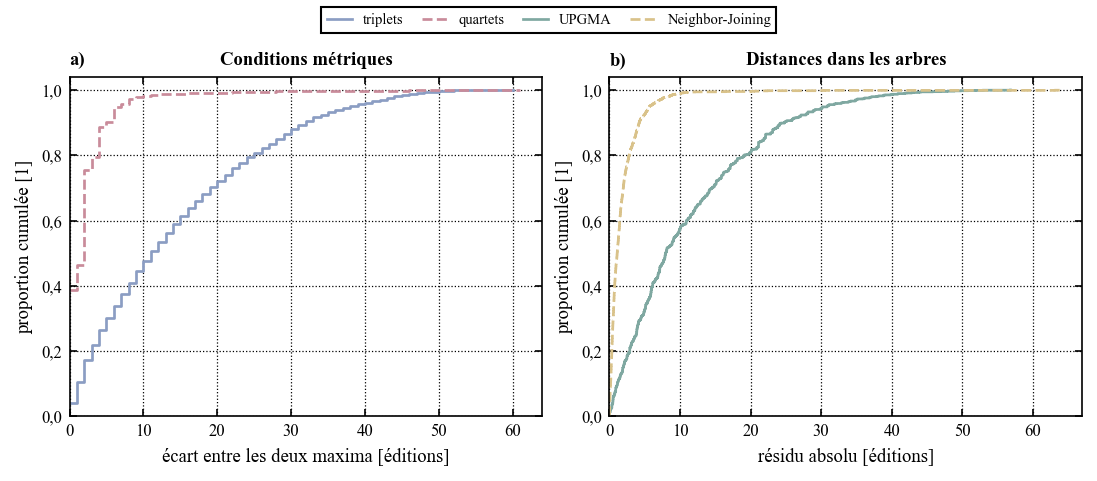

In [20]:
# Écarts aux conditions de distance et résidus de l'ajustement patristique.
phy_dir = RES / "phylogeny/phix174"
phy_gaps = nv_csv(phy_dir / "gaps.csv")
phy_fit = nv_csv(phy_dir / "pair_fit.csv")
assert len(phy_fit) == 2016
assert phy_gaps.groupby("criterion")["count"].sum().to_dict() == {"ultrametric": 41664, "four_point": 635376}
phy_fig, phy_ax = plt.subplots(1, 2, figsize=(7.2, 3.1))
for phy_ix, (phy_key, phy_name) in enumerate([("ultrametric", "triplets"), ("four_point", "quartets")]):
    phy_counts = phy_gaps[phy_gaps.criterion.eq(phy_key)].sort_values("gap")
    phy_ax[0].step(phy_counts.gap, phy_counts["count"].cumsum()/phy_counts["count"].sum(),
                   where="post", color=COLORS[phy_ix], ls=["-", "--"][phy_ix], label=phy_name)
for phy_ix, (phy_col, phy_algorithm) in enumerate([("upgma_path", "UPGMA"), ("nj_path", "Neighbor-Joining")]):
    phy_abs = np.sort((phy_fit[phy_col] - phy_fit.edit_distance).abs().to_numpy())
    phy_ax[1].step(phy_abs, np.arange(1, len(phy_abs)+1)/len(phy_abs),
                   where="post", color=COLORS[phy_ix+2], ls=["-", "--"][phy_ix], label=phy_algorithm)
phy_ax[0].set(xlabel="écart entre les deux maxima [éditions]", ylabel="proportion cumulée [1]")
phy_ax[1].set(xlabel="résidu absolu [éditions]", ylabel="proportion cumulée [1]")
for phy_axis in phy_ax:
    phy_axis.set(xlim=(0, None), ylim=(0, 1.04))
label_panels(phy_ax)
column_titles(phy_ax, ('Conditions métriques', 'Distances dans les arbres'))
legend_above(phy_fig, phy_ax, ncol=4)
nv_save(phy_fig, "16_phylogenie")

*Figure 19.* La proportion cumulée de triplets et de quartets donne la distribution des écarts aux deux conditions. Les résidus comparent ensuite la longueur du chemin dans chaque arbre à la distance globale observée entre les mêmes feuilles.

<sub>Code : [scripts/tree.py](../scripts/tree.py), [results/romeo/cohort-837271/matrix.tsv](../results/romeo/cohort-837271/matrix.tsv), [results/romeo/cohort-837271/upgma.nwk](../results/romeo/cohort-837271/upgma.nwk), [results/romeo/cohort-837271/nj.nwk](../results/romeo/cohort-837271/nj.nwk), [results/phylogeny/phix174/gaps.csv](../results/phylogeny/phix174/gaps.csv), [results/phylogeny/phix174/pair_fit.csv](../results/phylogeny/phix174/pair_fit.csv), [results/phylogeny/phix174/fit.csv](../results/phylogeny/phix174/fit.csv), [results/ncbi/phix174.tsv](../results/ncbi/phix174.tsv), [results/phylogeny/phix174/branches.csv](../results/phylogeny/phix174/branches.csv), [results/phylogeny/phix174/duplicate_sensitivity.csv](../results/phylogeny/phix174/duplicate_sensitivity.csv).</sub>

Les distances d’édition entre phages vont de 0 à 134, avec une médiane de 55. Seuls 1 661 des 41 664 triplets satisfont l’égalité ultramétrique. Parmi 635 376 quartets, 245 847 satisfont la condition des quatre points. L’erreur absolue maximale atteint toutefois 56,87 et 63,86 éditions respectivement. Neighbor-Joining réduit ainsi l’erreur moyenne sur ces paires tout en donnant le plus grand écart individuel. Les accessions HM753660.1 et HM753661.1 sont identiques dans la matrice. En retirant une copie, 38 275 des 39 711 triplets et 368 769 des 595 665 quartets présentent encore un écart. Pour chaque arête, la RMSE calculée sur les paires qui la traversent se situe entre 9,62 et 26,63 éditions avec UPGMA et entre 0,98 et 11,98 avec Neighbor-Joining.

Les coûts de calcul et l’ajustement aux distances éclairent le choix de la méthode pour une collection.

<p><strong><u>Synthèse.</u></strong> L’erreur quadratique moyenne des distances patristiques a pour racine 14,89 éditions sous UPGMA et 3,56 sous Neighbor-Joining.<br>La plus grande erreur individuelle reste plus élevée sous Neighbor-Joining sur cette collection.</p>

<a id="groupes-surveillance"></a>

## Concordance avec les groupes de surveillance

<hr>

La figure 20 confronte les distances au sein des groupes de surveillance à leur récupération par les reconstructions d’arbres.

Pour une partition en groupes, le nombre de paires intra-groupes vaut $\sum_g n_g(n_g-1)/2$. Un groupe est retrouvé lorsqu’une arête de longueur positive sépare exactement ses feuilles. Pour Neighbor-Joining, les deux côtés de l’arête sont examinés. La proportion représentée vaut $G_{\rm retrouvés}/G_{\rm évaluables}$.

Le panel SARS-CoV-2 comprend 64 accessions. Sept groupes de neuf séquences fournissent les comparaisons intra et inter-groupes. La référence isolée participe à la matrice, puis sort de ce contraste. Edlib, WFA2-lib et NvPD retrouvent les 2 016 distances globales avec une comparaison littérale des symboles. Les deux arbres des distances utilisent les 64 feuilles. L’arbre de surveillance UShER publié par UCSC couvre 52 accessions, avec au moins deux représentants pour six groupes. Les longueurs des branches UShER représentent des mutations sur un arbre de placement. [Turakhia et coll., 2021](https://doi.org/10.1038/s41588-021-00862-7)

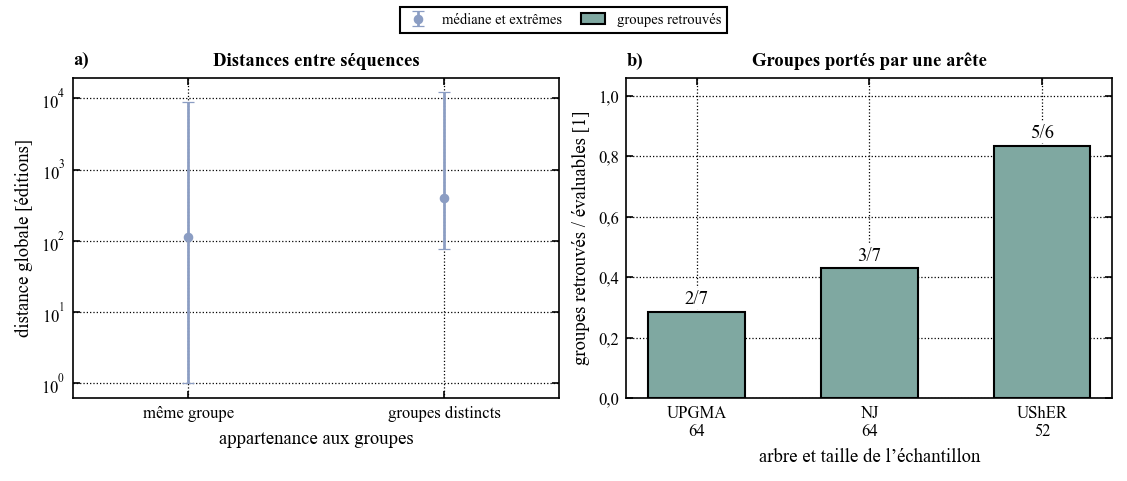

In [21]:
# Distances agrégées et groupes reconnus sur des arbres aux couvertures différentes.
sv_edit_dir = RES / "phylogeny/sars-edit"
sv_public_dir = RES / "phylogeny/sars-surveillance"
sv_verify = nv_csv(sv_edit_dir / "verification.csv")
assert sv_verify.records.eq(64).all() and sv_verify.pairs.eq(2016).all()
assert {"edlib","wfa2"} <= set(sv_verify.algorithm) and sv_verify.matrix_sha256.nunique()==1
sv_dist = nv_csv(sv_edit_dir / "pooled_distances.csv").set_index("comparison").loc[["within","between"]]
sv_public_groups = nv_csv(sv_public_dir / "group_clades.csv")
sv_groups = pd.concat([nv_csv(sv_edit_dir / "group_clades.csv"), sv_public_groups[sv_public_groups.tree.eq("public")]])
sv_groups = sv_groups[sv_groups.members.ge(2)].copy()
sv_groups["positive_edge_match"] = pd.to_numeric(sv_groups.positive_edge_match)
sv_match = sv_groups.groupby("tree").positive_edge_match.agg(["sum","count"]).loc[["upgma","nj","public"]]
assert sv_match["count"].tolist()==[7,7,6] and sv_match["sum"].tolist()==[2,3,5]
sv_splits = nv_csv(sv_public_dir / "shared_splits.csv")
assert sv_splits.tips.eq(52).all()
sv_fig, sv_ax = plt.subplots(1, 2, figsize=(7.4, 3.1))
sv_x = np.arange(2)
sv_ax[0].errorbar(sv_x, sv_dist["median"], yerr=[sv_dist["median"]-sv_dist["min"],sv_dist["max"]-sv_dist["median"]],
                  fmt="o",color=COLORS[0],capsize=3,label="médiane et extrêmes")
sv_ax[0].set(yscale="log", ylabel="distance globale [éditions]", xlabel="appartenance aux groupes", xlim=(-.45,1.45))
sv_ax[0].set_xticks(sv_x, ["même groupe","groupes distincts"])
sv_fraction = sv_match["sum"] / sv_match["count"]
sv_ax[1].bar(np.arange(3),sv_fraction.values,width=.56,color=COLORS[2],edgecolor=INK,label="groupes retrouvés")
for sv_i,(sv_kind,sv_row) in enumerate(sv_match.iterrows()):
    sv_ax[1].annotate(f"{int(sv_row['sum'])}/{int(sv_row['count'])}",(sv_i,sv_fraction.loc[sv_kind]),
                      xytext=(0,4),textcoords="offset points",ha="center",
                      bbox=dict(facecolor=PAPER, edgecolor=PAPER, pad=.4))
sv_ax[1].set(ylabel="groupes retrouvés / évaluables [1]", xlabel="arbre et taille de l’échantillon",ylim=(0,1.06))
sv_ax[1].set_xticks(np.arange(3),["UPGMA\n64", "NJ\n64", "UShER\n52"])
label_panels(sv_ax)
column_titles(sv_ax, ('Distances entre séquences', 'Groupes portés par une arête'))
legend_above(sv_fig, sv_ax, ncol=2)
nv_save(sv_fig, "19_phylogenie_surveillance")

*Figure 20.* Les points en a) donnent les médianes des distances d’édition et les segments leur étendue. Le panneau b) compte les groupes entièrement séparés par une arête positive parmi ceux représentés dans chaque arbre. Les dénominateurs distinguent les deux échantillons.

<sub>Code : [scripts/phylo_groups.py](../scripts/phylo_groups.py), [results/phylogeny/sars-edit/verification.csv](../results/phylogeny/sars-edit/verification.csv), [results/phylogeny/sars-edit/pooled_distances.csv](../results/phylogeny/sars-edit/pooled_distances.csv), [results/phylogeny/sars-edit/group_clades.csv](../results/phylogeny/sars-edit/group_clades.csv), [results/phylogeny/sars-surveillance/group_clades.csv](../results/phylogeny/sars-surveillance/group_clades.csv), [results/phylogeny/sars-surveillance/shared_splits.csv](../results/phylogeny/sars-surveillance/shared_splits.csv), [results/phylogeny/sars-edit/censored.csv](../results/phylogeny/sars-edit/censored.csv), [results/phylogeny/sars-surveillance/overlap.csv](../results/phylogeny/sars-surveillance/overlap.csv).</sub>

Les 252 paires d’un même groupe ont une distance médiane de 112 éditions. Pour les 1 701 paires entre groupes, la médiane atteint 402. UPGMA retrouve deux des sept groupes et Neighbor-Joining en retrouve trois. Sur les feuilles représentées dans la référence publique, UShER en retrouve cinq sur six. Une comparaison distincte reconstruit les deux arbres de distances sur les mêmes 52 feuilles. Parmi les 27 bipartitions non triviales de longueur positive dans l’arbre public, six apparaissent sous UPGMA et huit sous Neighbor-Joining. Ce recouvrement décrit les topologies pour la sélection observée. NvPD a vérifié séparément les 2 016 coûts en 268,83 s sur Apple M1 Pro, en distribuant les paires entre six processus à un fil. Le calcul qui répartissait huit fils sur les colonnes d’une seule paire a atteint sa limite de 1 200 s pour la matrice. La comparaison littérale inclut 65 588 symboles ambigus sur 1 905 372 caractères.

Le choix d’un calcul de distance gagne ainsi à préciser le coût observé et l’usage prévu des résultats.

<p><strong><u>Synthèse.</u></strong> Sur les 1 326 paires communes, la corrélation de Pearson entre distance d’édition et chemin UShER vaut 0,124.<br>Les deux mesures portent sur des objets différents, les chaînes déposées et les branches d’un arbre de placement.</p>

<a id="synthese"></a>

## Synthèse des critères de choix

<hr>

La figure 21 compare le temps par paire et le débit d’une collection pour situer le choix de l’algorithme et de sa répartition.

Pour deux chaînes $a,b$, la distance $d(a,b)=\min_{\pi}(\#\mathrm{insertions}+\#\mathrm{suppressions}+\#\mathrm{substitutions})$ minimise le coût parmi les alignements globaux $\pi$. Une programmation dynamique dense parcourt $mn$ cases. Une méthode sensible au score réduit le nombre d’états à explorer lorsque $d$ est faible. Pour $N$ séquences, le lot contient $P=N(N-1)/2$ comparaisons indépendantes et son débit vaut $P/T$.

La synthèse reprend deux expériences indépendantes. La première compare, après lecture du FASTA, NvPD sur GH200 aux bibliothèques monothread de la campagne initiale sur les mêmes paires. La seconde mesure le débit de matrices complètes avec un ou deux nœuds EPYC, chacune contenant 64 séquences. Chaque panneau conserve son propre matériel et son périmètre de temps.

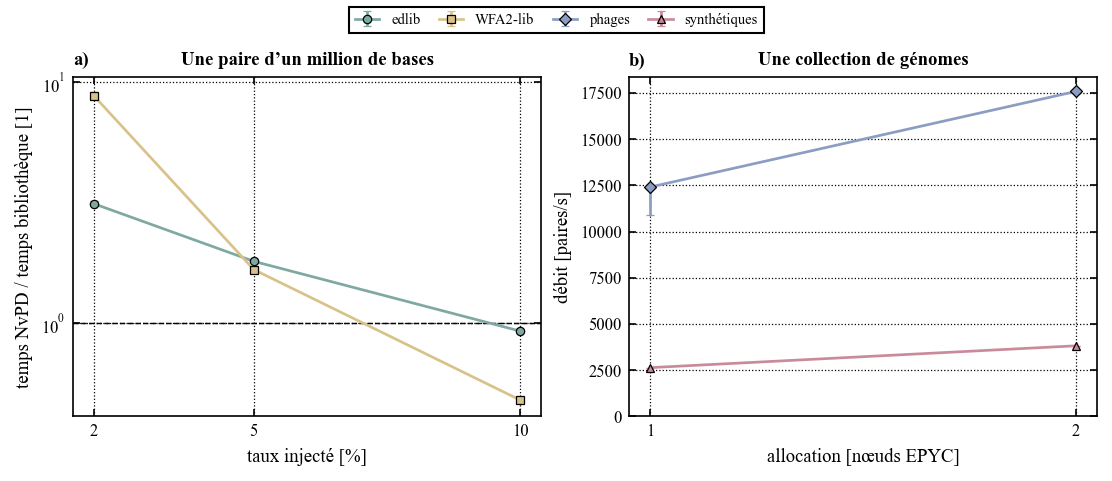

In [22]:
# Choix de la méthode et débit des collections, à partir des mesures brutes.
sy_files = sorted((RES / "romeo").glob("*-*.csv"))
sy_raw = pd.concat([nv_csv(sy_file) for sy_file in sy_files])
sy_methods = ["nvpd-cuda", "edlib", "wfa2"]
sy_pairs = sy_raw[sy_raw.length.eq(1_000_000) & sy_raw.algorithm.isin(sy_methods)]
assert sy_pairs.groupby("input_sha256").distance.nunique().eq(1).all()
sy_times = sy_pairs.pivot_table(index=["rate","input_sha256"], columns="algorithm", values="seconds", aggfunc="median")
assert sy_times.notna().all().all()
sy_batch = nv_csv(RES / "mpi/838226/trials.csv")
sy_batch = sy_batch[sy_batch.case.isin(["synthetic64","phix64"])]
assert sy_batch.pairs.eq(2016).all()
sy_fig, sy_ax = plt.subplots(1, 2, figsize=(7.3, 3.1))
for sy_ix, (sy_alg, sy_label) in enumerate([("edlib", "edlib"), ("wfa2", "WFA2-lib")]):
    sy_ratio = (sy_times["nvpd-cuda"]/sy_times[sy_alg]).reset_index(level="input_sha256", drop=True)
    sy_ratio.index = sy_ratio.index * 100
    nv_band(sy_ax[0], sy_ratio, COLORS[sy_ix+2], sy_label, "os"[sy_ix])
sy_ax[0].axhline(1, **GUIDE)
sy_ax[0].set(xlabel="taux injecté [%]", ylabel="temps NvPD / temps bibliothèque [1]", yscale="log")
sy_ax[0].set_xticks([2,5,10])
for sy_ix, (sy_case, sy_label) in enumerate([("phix64", "phages"), ("synthetic64", "synthétiques")]):
    sy_lot = sy_batch[sy_batch.case.eq(sy_case)].set_index("nodes")
    nv_band(sy_ax[1], sy_lot.pairs / sy_lot.seconds, COLORS[sy_ix], sy_label, "D^"[sy_ix])
sy_ax[1].set(xlabel="allocation [nœuds EPYC]", ylabel="débit [paires/s]", ylim=(0, None))
sy_ax[1].set_xticks([1,2])
label_panels(sy_ax)
column_titles(sy_ax, ('Une paire d’un million de bases', 'Une collection de génomes'))
legend_above(sy_fig, sy_ax, ncol=4)
nv_save(sy_fig, "17_synthese")

# Planche du carnet dans son ordre de lecture.
ct_plot.montage(FIG, [
    ('01_temps_distance.png', 'Coût du calcul de la distance globale'),
    ('02_echelle_cpu.png', 'Passage à l’échelle sur un processeur'),
    ('13_openmp_un_million.png', 'Anti-diagonales et lignes de grande largeur'),
    ('03_variantes_cpu.png', 'Vectorisation de la récurrence de dernière occurrence'),
    ('04_memoire_cpu.png', 'Occupation mémoire et défauts du cache de données'),
    ('21_trace_lineaire.png', 'Reconstruction de l’alignement en espace linéaire'),
    ('05_cout_instructions.png', 'Instructions et prédictions de branchement'),
    ('06_variantes_gpu.png', 'Regroupement des lignes en tuiles CUDA'),
    ('07_trace_cuda.png', 'Chronologie des appels hôte et des noyaux CUDA'),
    ('14_localite_gpu.png', 'Localité des lectures en mémoire globale'),
    ('20_front_gpu.png', 'Calcul par fronts de coût sur accélérateur'),
    ('08_allocations_cuda.png', 'Réutilisation des tampons entre alignements'),
    ('09_portage_kokkos.png', 'Portabilité de la récurrence avec Kokkos'),
    ('10_echelle_mpi.png', 'Passage à l’échelle fort entre nœuds'),
    ('15_mpi_faible.png', 'Passage à l’échelle faible entre nœuds'),
    ('11_chromosome21.png', 'Distances entre assemblages d’un chromosome humain'),
    ('18_chromosomes_entiers.png', 'Comparaison de chromosomes humains entiers'),
    ('12_methodes_exactes.png', 'Méthodes exactes sensibles à la distance'),
    ('16_phylogenie.png', 'Structure des distances entre génomes de phages'),
    ('19_phylogenie_surveillance.png', 'Concordance avec les groupes de surveillance'),
    ('17_synthese.png', 'Synthèse des critères de choix'),
])

*Figure 21.* Sur les longues paires, un rapport supérieur à un indique que la bibliothèque CPU termine avant le noyau NvPD. Pour les matrices, un point donne le nombre d’alignements calculés par seconde à partir du temps médian de trois essais.

<sub>Code : [bench/run.py](../bench/run.py), [results/romeo](../results/romeo/), [bench/mpi_benchmark.py](../bench/mpi_benchmark.py), [results/mpi/838226/trials.csv](../results/mpi/838226/trials.csv).</sub>

Sur les paires d’un million de bases, le rapport des temps NvPD/edlib passe de 3,12 à 2 % d’erreur à 0,92 à 10 %. À deux nœuds, le programme MPI traite environ 17 586 paires de phages par seconde, contre 3 820 pour les séquences synthétiques plus longues. Le débit caractérise le jeu de données et la configuration d’exécution.

<p><strong><u>Synthèse.</u></strong> À un million de bases, le rapport médian NvPD/WFA2-lib vaut 8,74 à 2 % d’erreur et 0,48 à 10 %.<br>Pour une collection, répartir les paires permet d’augmenter le débit sans échanger chaque ligne.</p>